In [ ]:
import numpy as np
import pandas as pd
import time

import matplotlib.pyplot as plt
%matplotlib inline

import seaborn as sns
from scipy import stats
from scipy.stats import norm, skew
from scipy.special import boxcox1p
from scipy.stats import boxcox_normmax

from sklearn import preprocessing
from sklearn.preprocessing import StandardScaler

import sklearn
from sklearn import metrics
from sklearn.metrics import roc_curve,accuracy_score
from sklearn.metrics import classification_report,confusion_matrix
from sklearn.metrics import average_precision_score,precision_recall_curve

from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import GridSearchCV,RandomizedSearchCV

from sklearn.linear_model import Ridge,Lasso,LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegressionCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from xgboost import XGBClassifier
from xgboost import plot_importance
from sklearn.ensemble import AdaBoostClassifier

import warnings
warnings.filterwarnings("ignore")

In [ ]:
df=pd.read_csv('/content/creditcard.csv')
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [ ]:
df.shape

(284807, 31)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [ ]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [ ]:
df['Class'].value_counts()

,count
Class,
0,284315
1,492


Class
0    99.827251
1     0.172749
Name: Class, dtype: float64


<Axes: ylabel='Class'>

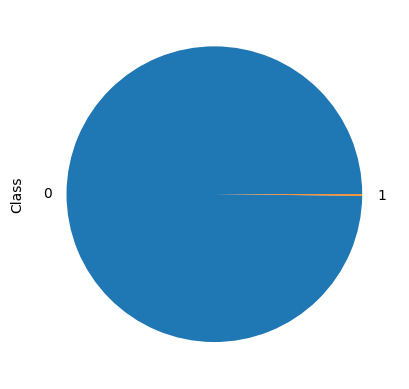

In [ ]:
print((df.groupby('Class')['Class'].count()/df['Class'].count())*100)
((df.groupby('Class')['Class'].count()/df['Class'].count())*100).plot.pie()

In [ ]:
classes=df['Class'].value_counts()
normal_share=classes[0]/df['Class'].count()*100
fraud_share=classes[1]/df['Class'].count()*100
print(normal_share)
print(fraud_share)

99.82725143693798
0.1727485630620034


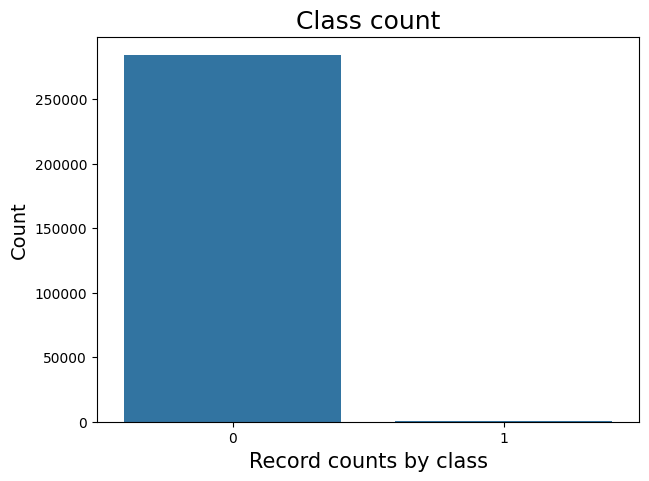

In [ ]:
plt.figure(figsize=(7,5))
sns.countplot(x='Class', data=df)
plt.title('Class count', fontsize=18)
plt.xlabel('Record counts by class', fontsize=15)
plt.ylabel('Count', fontsize=14)
plt.show()


In [ ]:
corr=df.corr()
corr

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
Time,1.000000,1.173963e-01,-1.059333e-02,-4.196182e-01,-1.052602e-01,1.730721e-01,-6.301647e-02,8.471437e-02,-3.694943e-02,-8.660434e-03,...,4.473573e-02,1.440591e-01,5.114236e-02,-1.618187e-02,-2.330828e-01,-4.140710e-02,-5.134591e-03,-9.412688e-03,-0.010596,-0.012323
V1,0.117396,1.000000e+00,4.135835e-16,-1.227819e-15,-9.215150e-16,1.812612e-17,-6.506567e-16,-1.005191e-15,-2.433822e-16,-1.513678e-16,...,-2.457409e-16,-4.290944e-16,6.168652e-16,-4.425156e-17,-9.605737e-16,-1.581290e-17,1.198124e-16,2.083082e-15,-0.227709,-0.101347
V2,-0.010593,4.135835e-16,1.000000e+00,3.243764e-16,-1.121065e-15,5.157519e-16,2.787346e-16,2.055934e-16,-5.377041e-17,1.978488e-17,...,-8.480447e-17,1.526333e-16,1.634231e-16,1.247925e-17,-4.478846e-16,2.057310e-16,-4.966953e-16,-5.093836e-16,-0.531409,0.091289
V3,-0.419618,-1.227819e-15,3.243764e-16,1.000000e+00,4.711293e-16,-6.539009e-17,1.627627e-15,4.895305e-16,-1.268779e-15,5.568367e-16,...,5.706192e-17,-1.133902e-15,-4.983035e-16,2.686834e-19,-1.104734e-15,-1.238062e-16,1.045747e-15,9.775546e-16,-0.210880,-0.192961
V4,-0.105260,-9.215150e-16,-1.121065e-15,4.711293e-16,1.000000e+00,-1.719944e-15,-7.491959e-16,-4.104503e-16,5.697192e-16,6.923247e-16,...,-1.949553e-16,-6.276051e-17,9.164206e-17,1.584638e-16,6.070716e-16,-4.247268e-16,3.977061e-17,-2.761403e-18,0.098732,0.133447
V5,0.173072,1.812612e-17,5.157519e-16,-6.539009e-17,-1.719944e-15,1.000000e+00,2.408382e-16,2.715541e-16,7.437229e-16,7.391702e-16,...,-3.920976e-16,1.253751e-16,-8.428683e-18,-1.149255e-15,4.808532e-16,4.319541e-16,6.590482e-16,-5.613951e-18,-0.386356,-0.094974
V6,-0.063016,-6.506567e-16,2.787346e-16,1.627627e-15,-7.491959e-16,2.408382e-16,1.000000e+00,1.191668e-16,-1.104219e-16,4.131207e-16,...,5.833316e-17,-4.705235e-19,1.046712e-16,-1.071589e-15,4.562861e-16,-1.357067e-16,-4.452461e-16,2.594754e-16,0.215981,-0.043643
V7,0.084714,-1.005191e-15,2.055934e-16,4.895305e-16,-4.104503e-16,2.715541e-16,1.191668e-16,1.000000e+00,3.344412e-16,1.122501e-15,...,-2.027779e-16,-8.898922e-16,-4.387401e-16,7.434913e-18,-3.094082e-16,-9.657637e-16,-1.782106e-15,-2.776530e-16,0.397311,-0.187257
V8,-0.036949,-2.433822e-16,-5.377041e-17,-1.268779e-15,5.697192e-16,7.437229e-16,-1.104219e-16,3.344412e-16,1.000000e+00,4.356078e-16,...,3.892798e-16,2.026927e-16,6.377260e-17,-1.047097e-16,-4.653279e-16,-1.727276e-16,1.299943e-16,-6.200930e-16,-0.103079,0.019875
V9,-0.008660,-1.513678e-16,1.978488e-17,5.568367e-16,6.923247e-16,7.391702e-16,4.131207e-16,1.122501e-15,4.356078e-16,1.000000e+00,...,1.936953e-16,-7.071869e-16,-5.214137e-16,-1.430343e-16,6.757763e-16,-7.888853e-16,-6.709655e-17,1.110541e-15,-0.044246,-0.097733


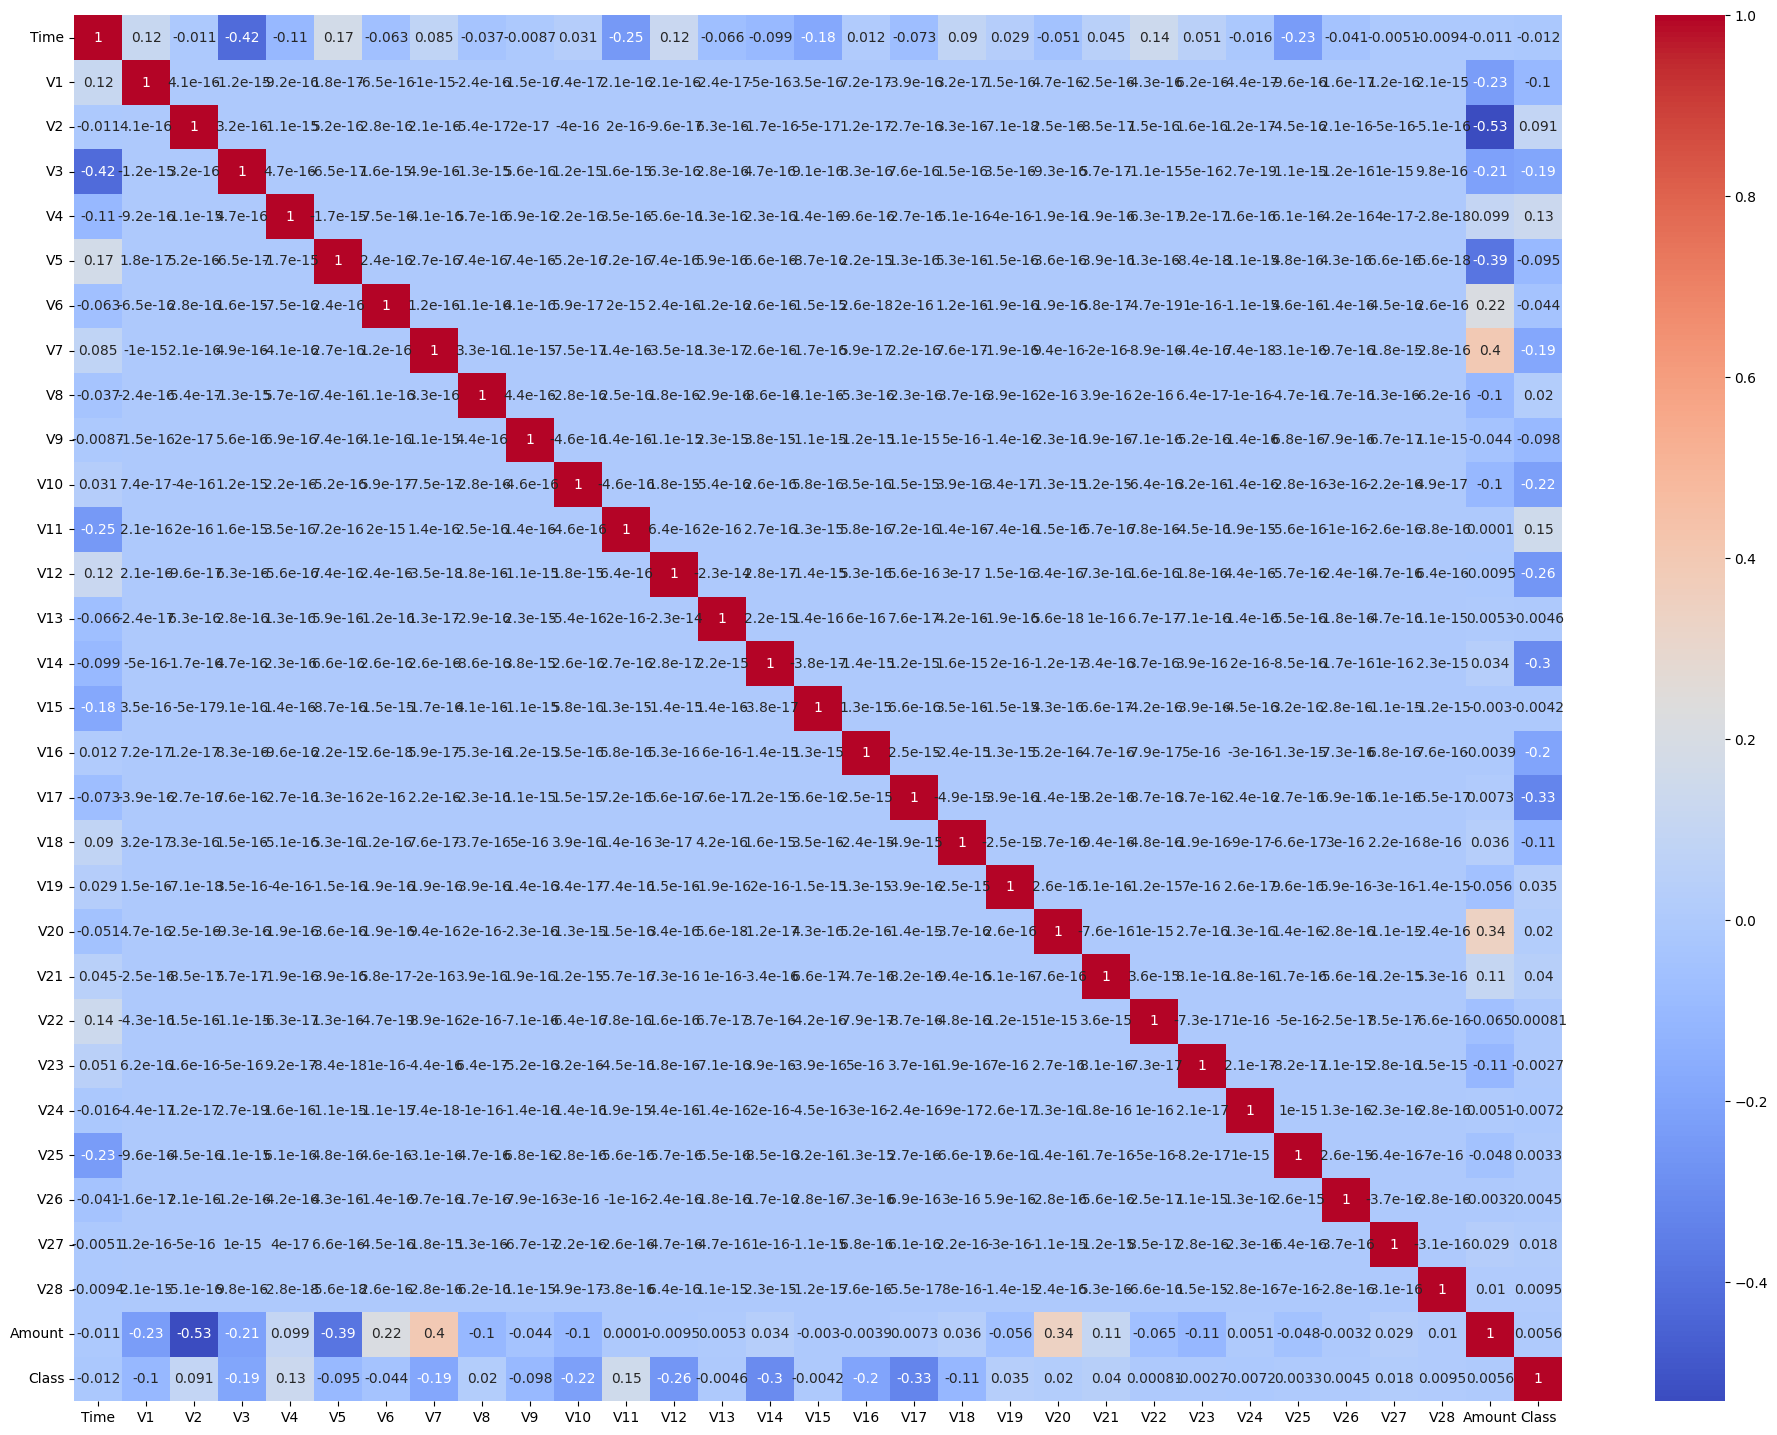

In [ ]:
plt.figure(figsize=(24,18))
sns.heatmap(corr,cmap='coolwarm',annot=True)
plt.show()

In [ ]:
Delta_Time=pd.to_timedelta(df['Time'],unit='s')

df['Time_Day']=(Delta_Time.dt.components.days).astype(int)
df["Time_Hour"]=(Delta_Time.dt.components.hours).astype(int)
df['Time_Min']=(Delta_Time.dt.components.minutes).astype(int)


In [ ]:
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class', 'Time_Day', 'Time_Hour', 'Time_Min'],
      dtype='object')

In [ ]:
df.drop(['Time_Day','Time_Min'],axis=1,inplace=True)
df.drop(['Time'],axis=1,inplace=True)

In [ ]:
df.columns

Index(['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11',
       'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21',
       'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class',
       'Time_Hour'],
      dtype='object')

In [ ]:
y=df['Class']
X=df.drop(['Class'],axis=1)

In [ ]:
X.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Time_Hour
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [ ]:
y.head()

,Class
0,0
1,0
2,0
3,0
4,0


In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=100,test_size=0.20)

In [ ]:
print(np.sum(y))
print(np.sum(y_train))
print(np.sum(y_test))

492
396
96


In [ ]:
cols=list(X.columns.values)

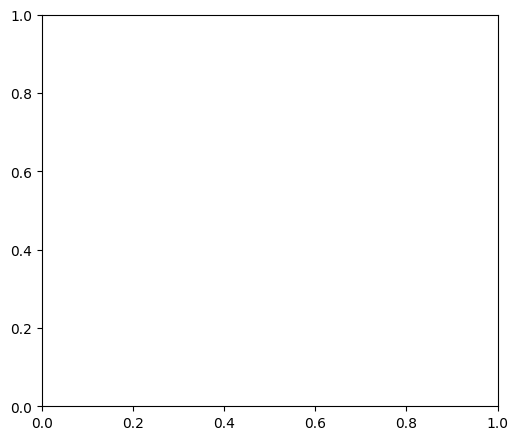

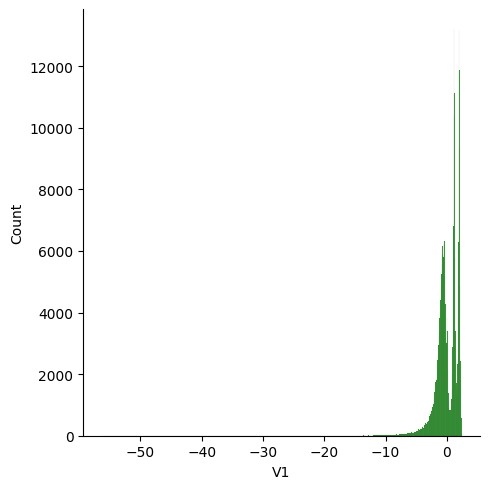

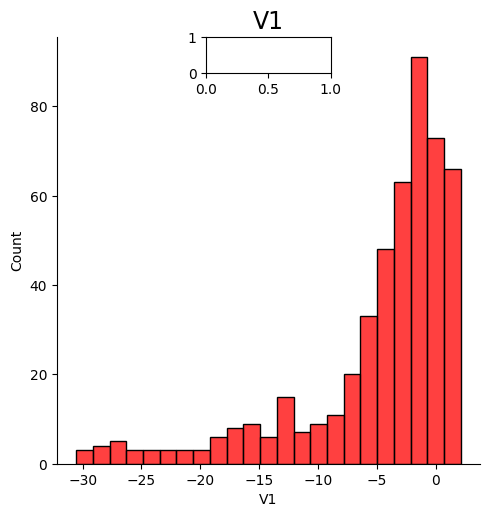

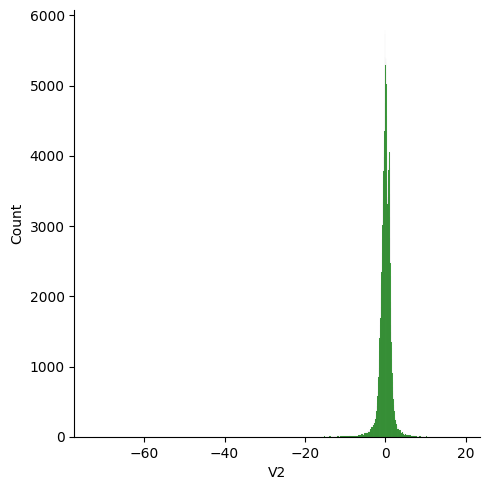

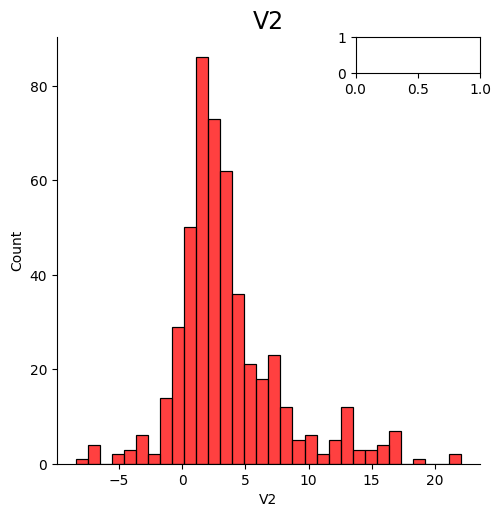

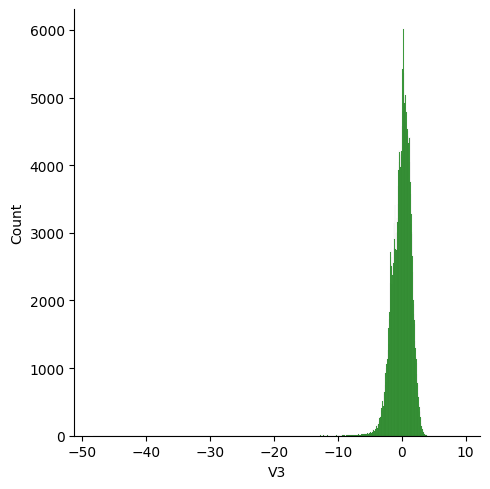

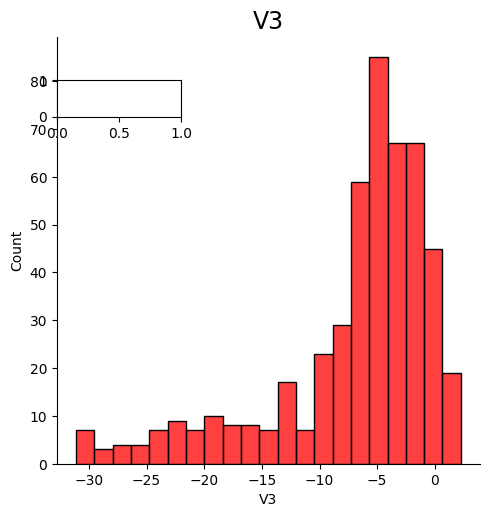

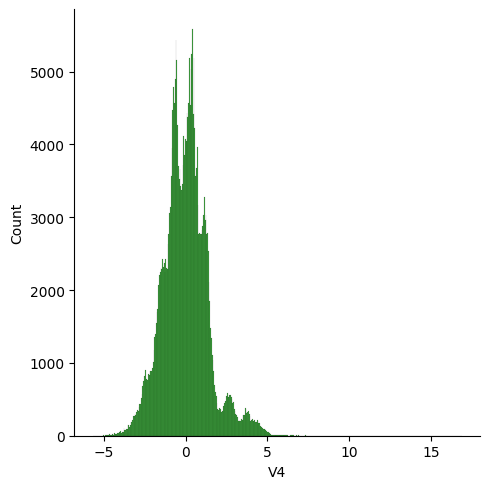

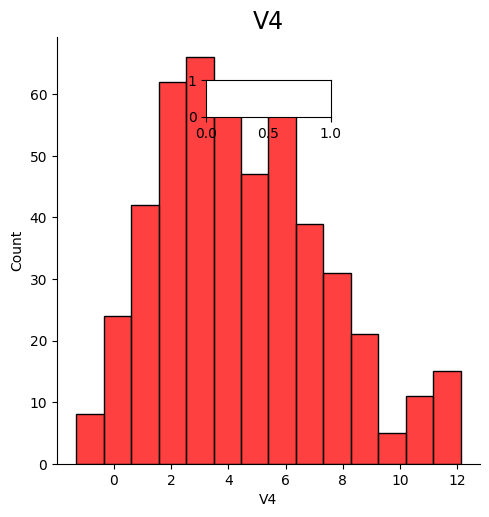

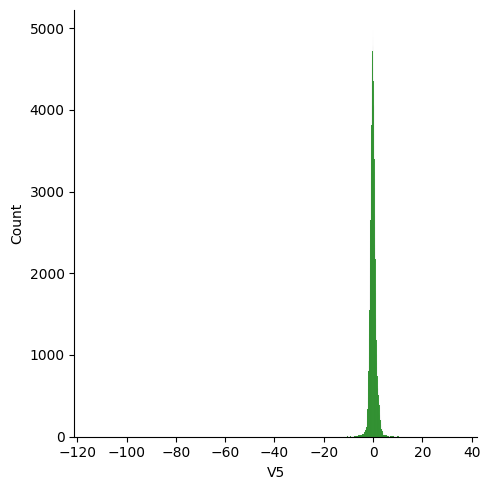

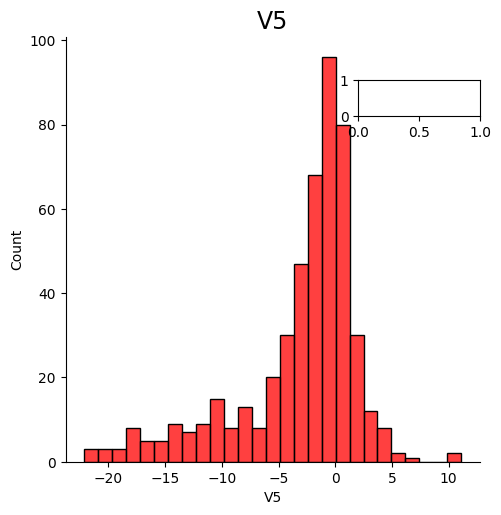

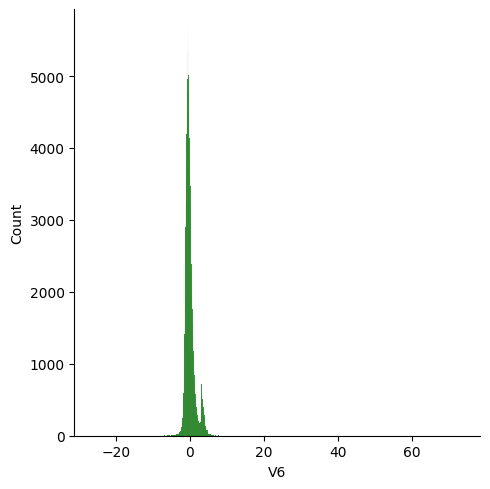

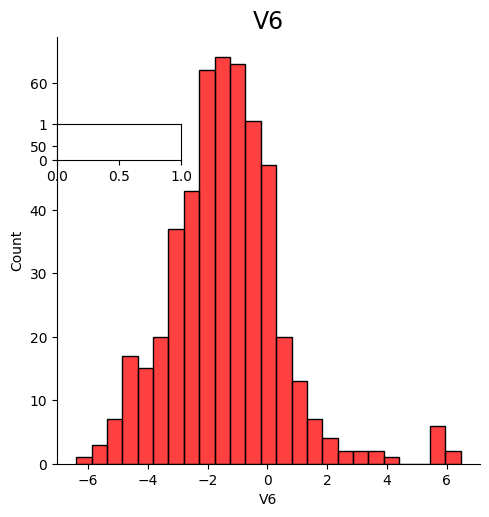

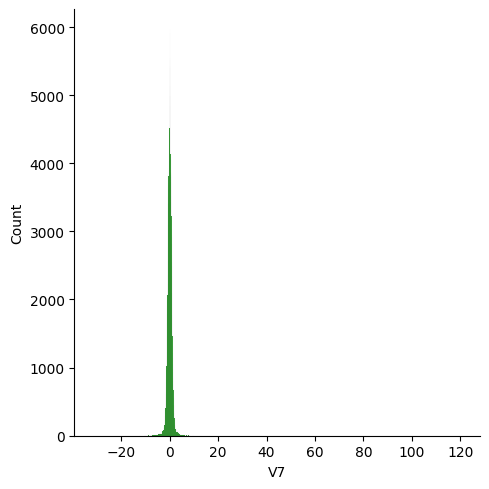

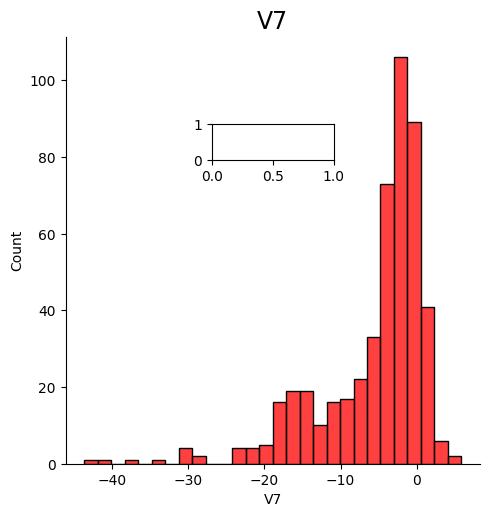

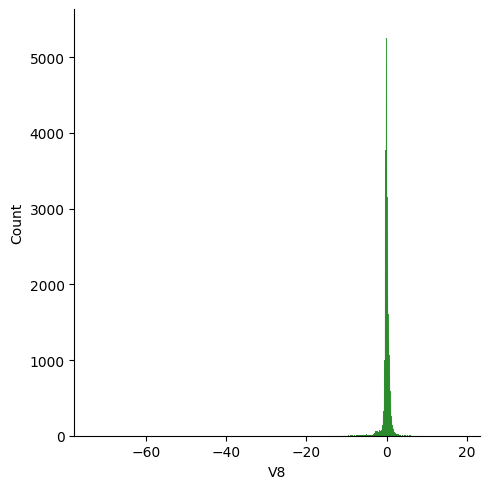

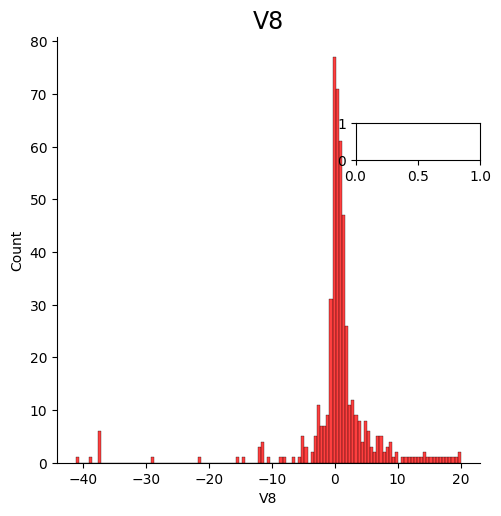

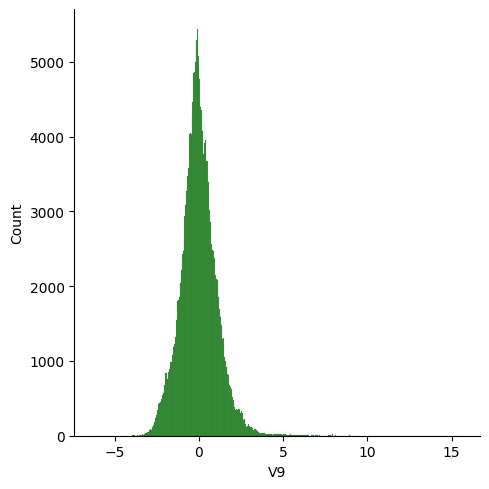

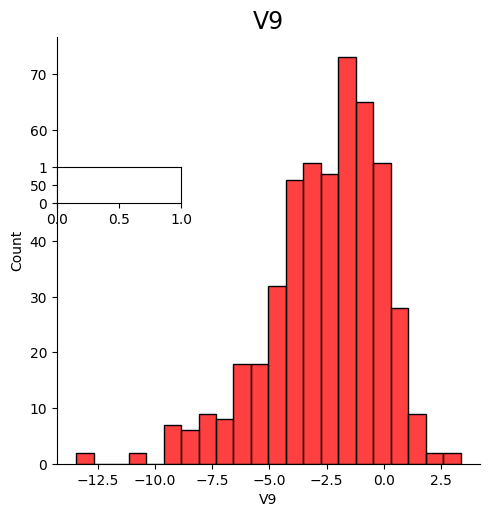

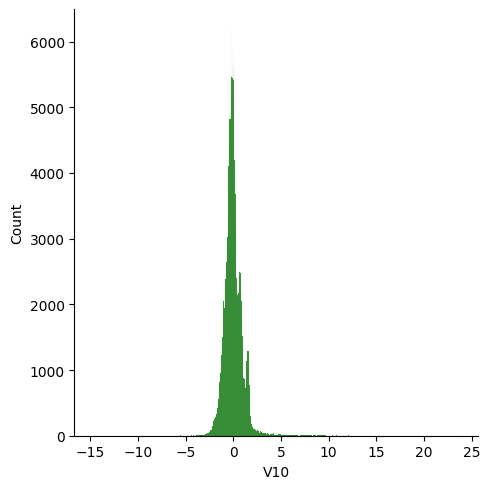

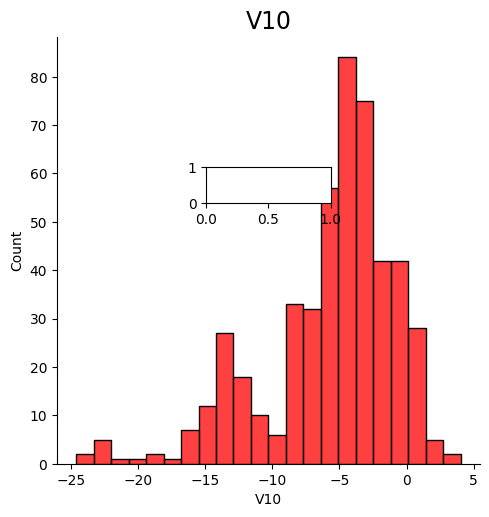

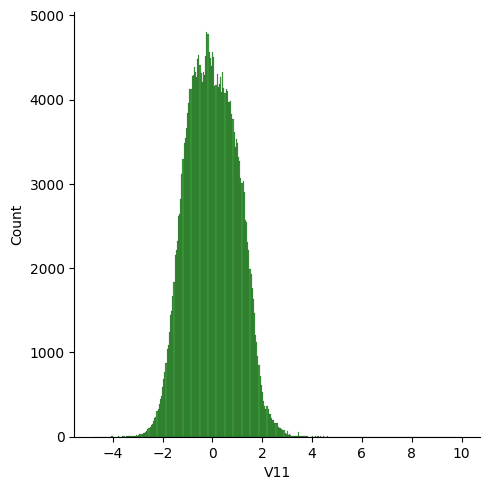

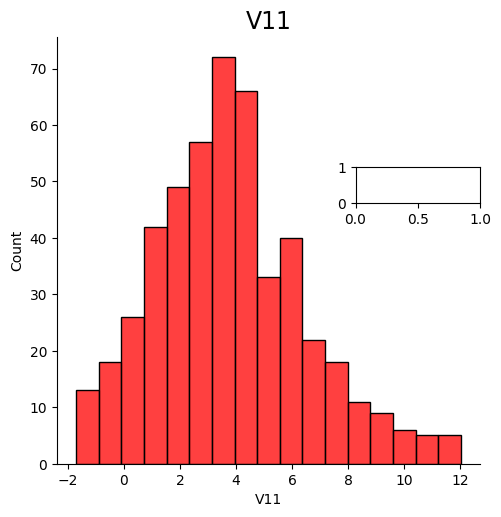

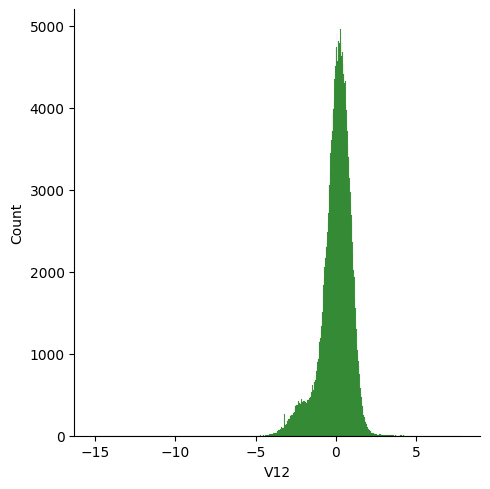

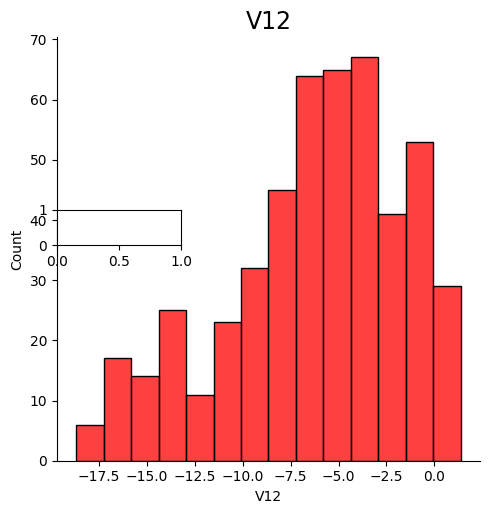

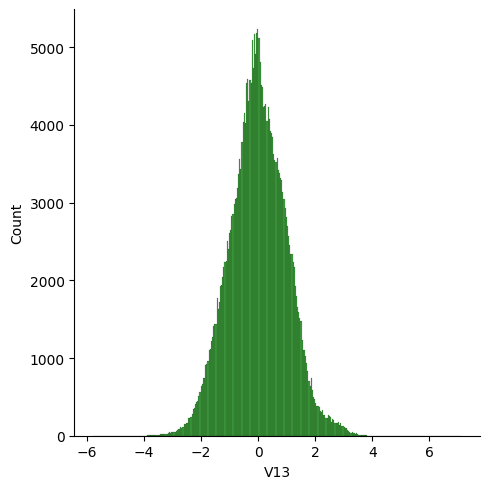

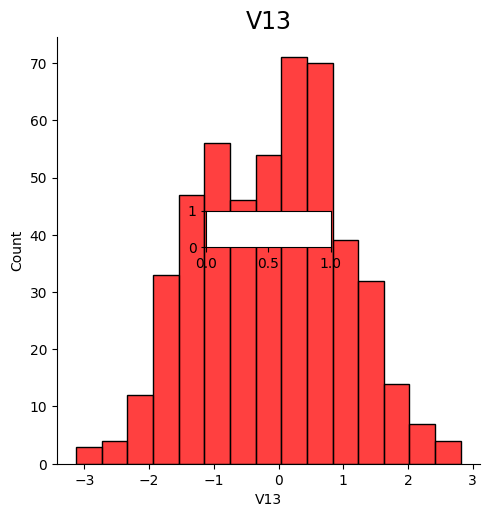

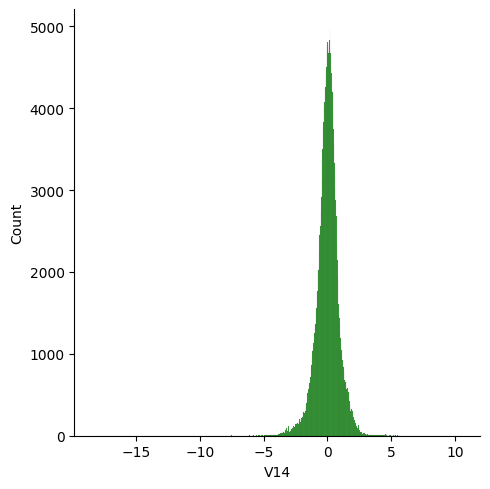

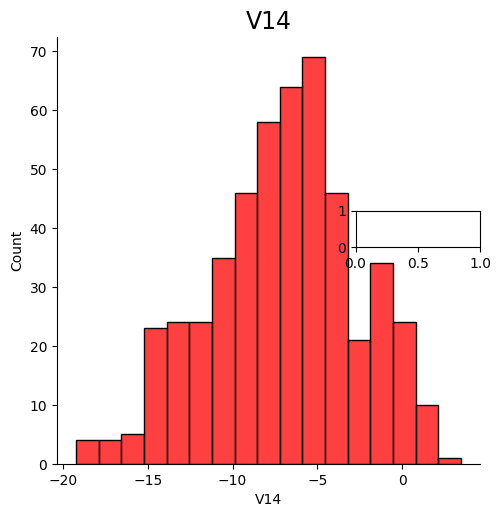

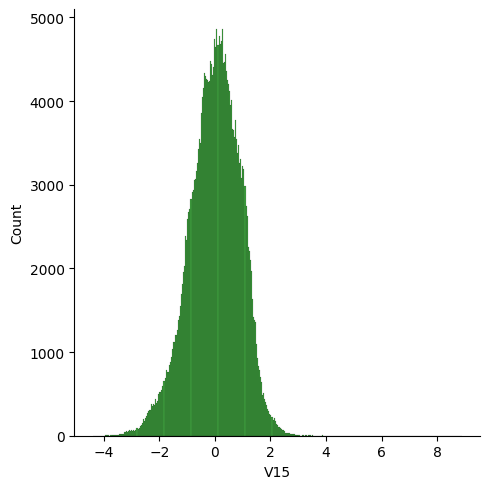

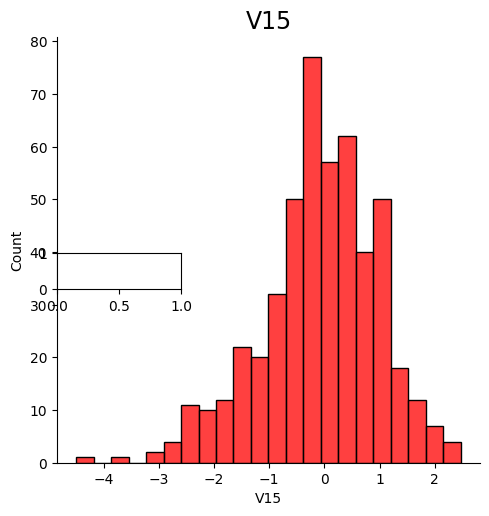

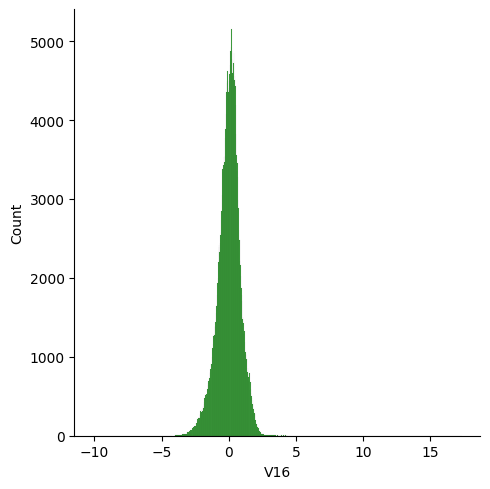

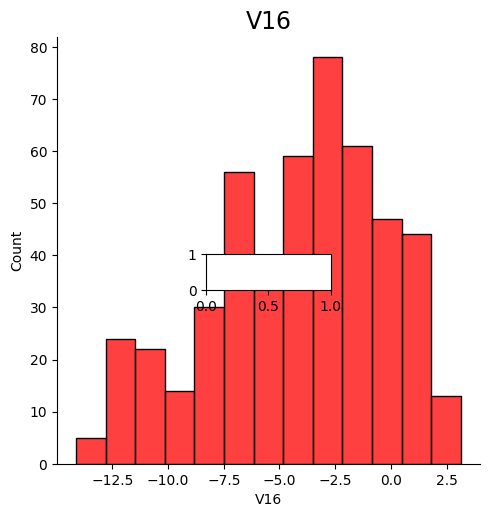

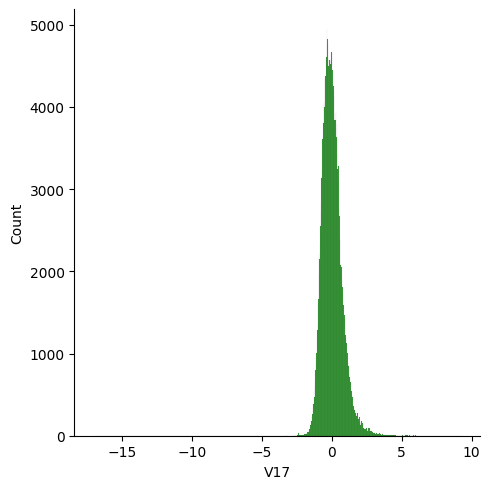

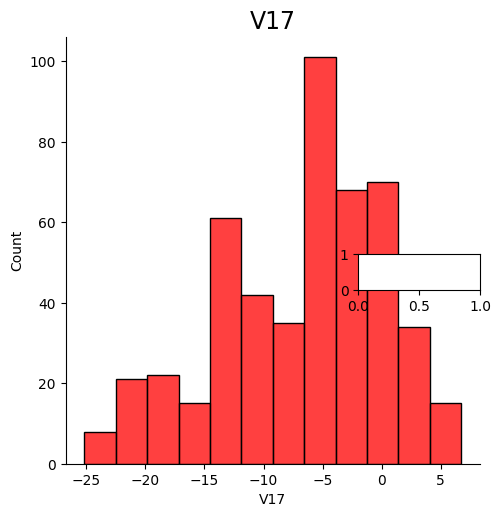

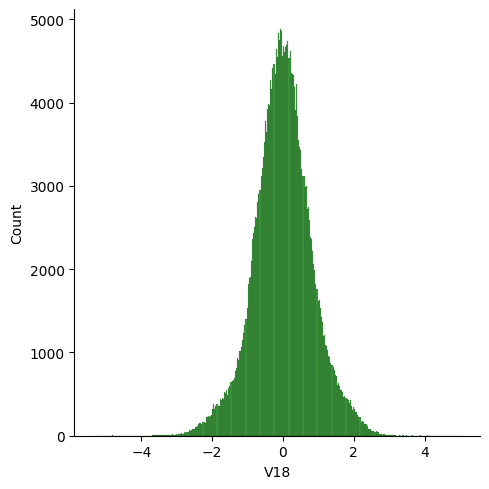

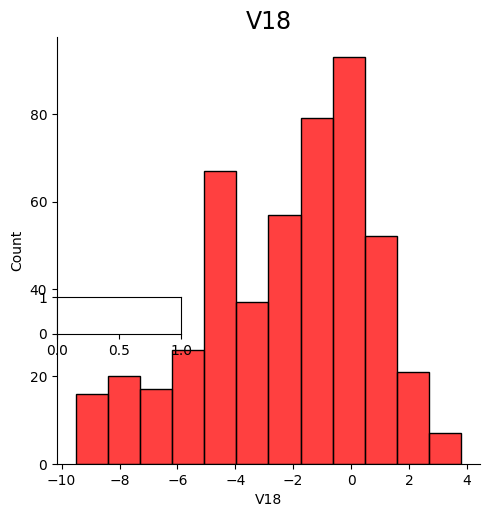

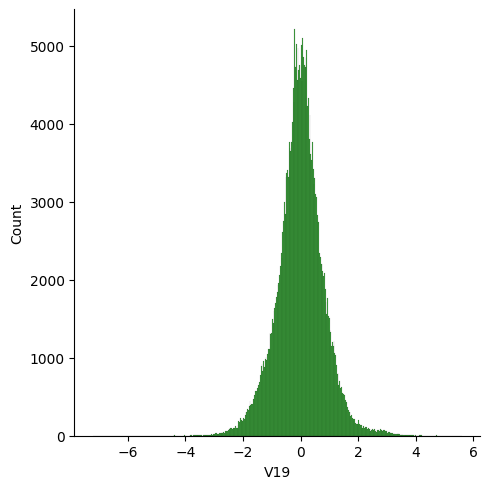

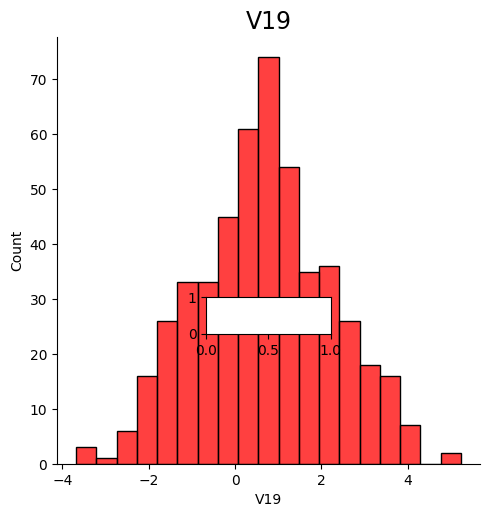

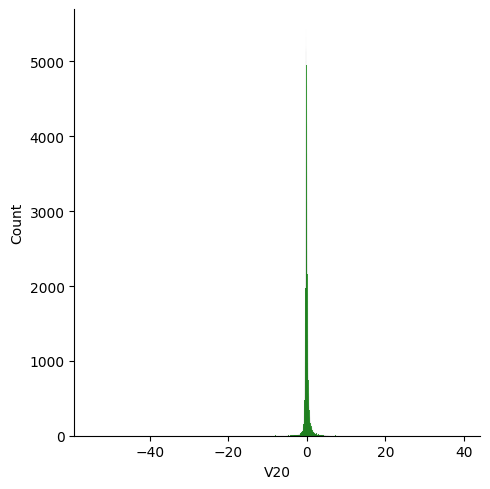

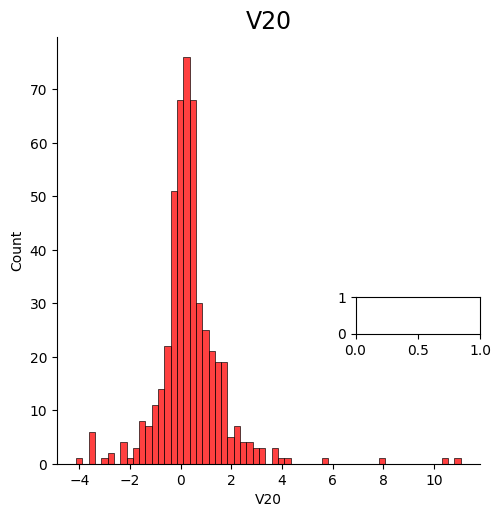

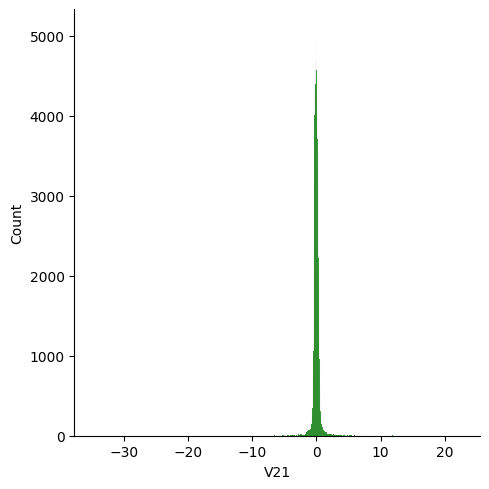

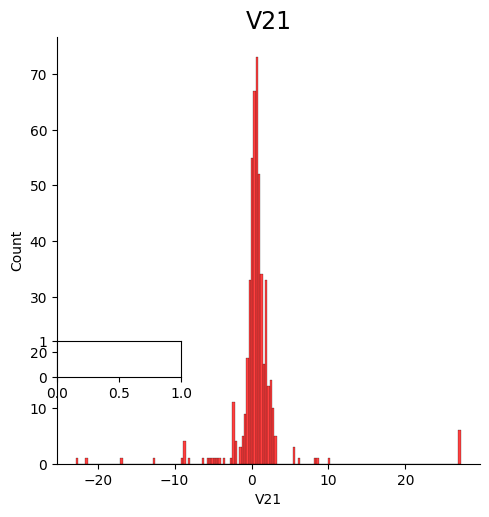

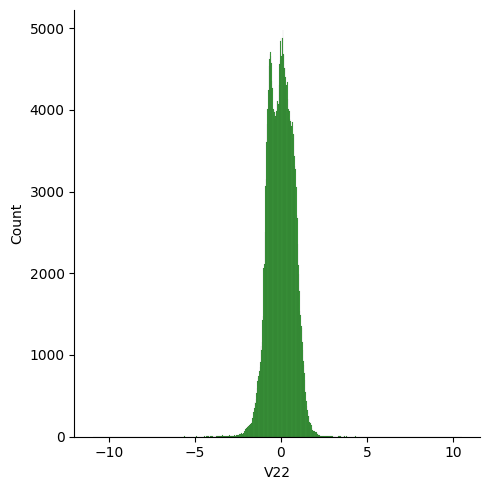

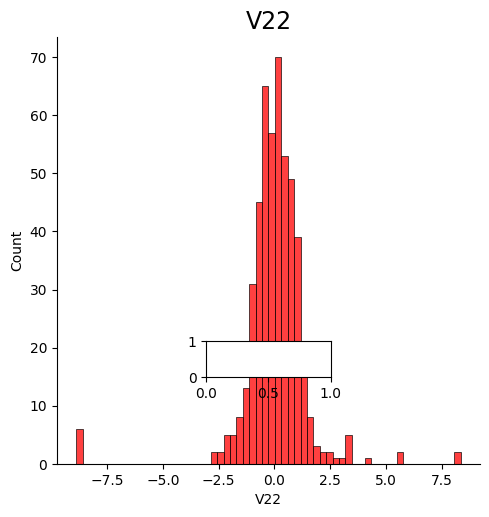

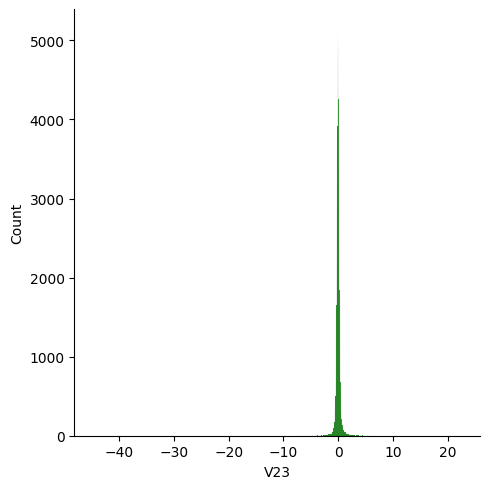

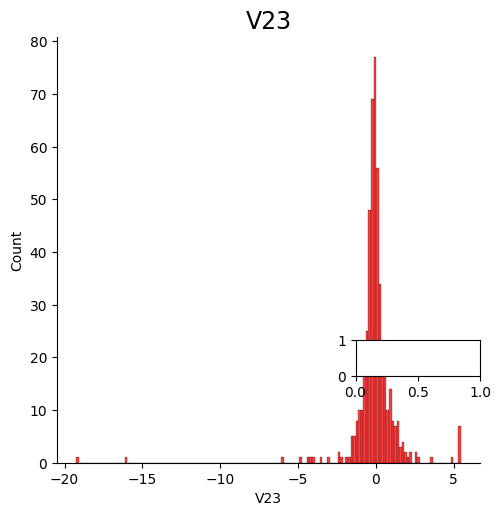

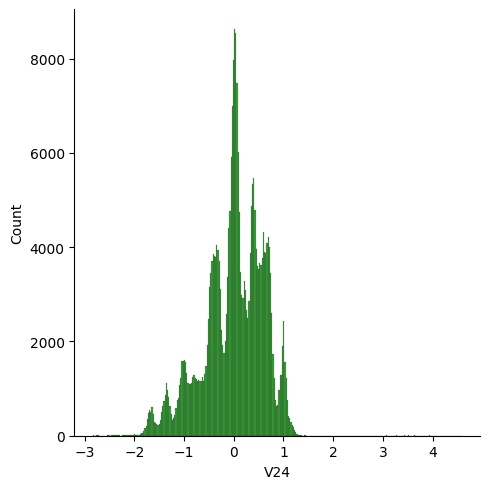

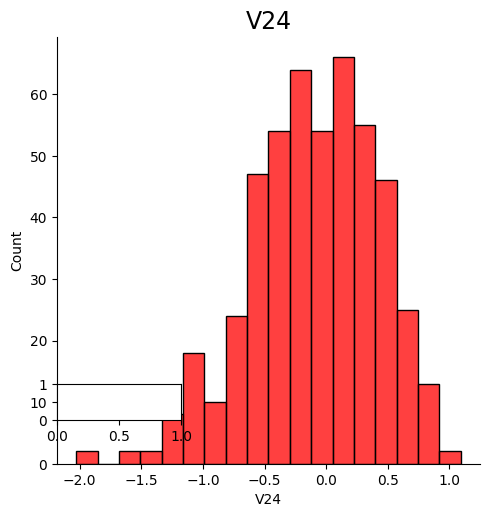

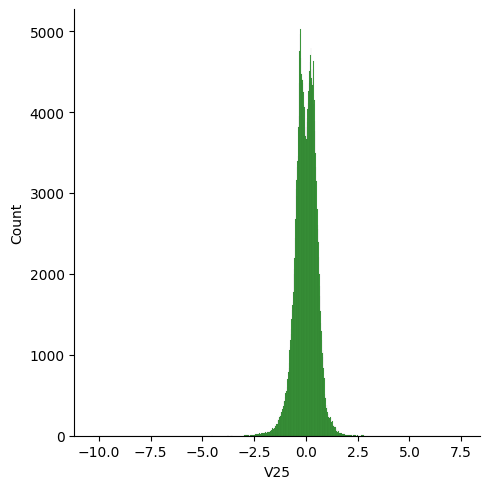

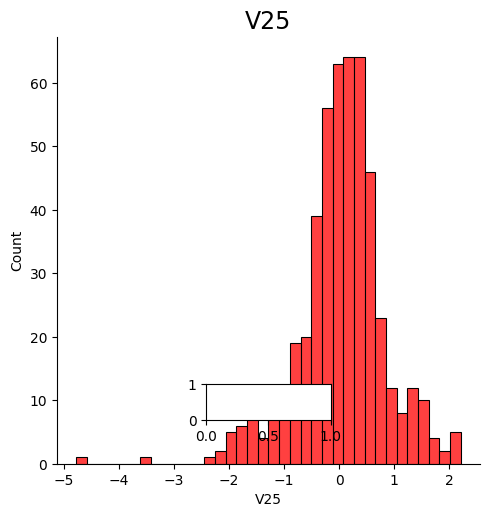

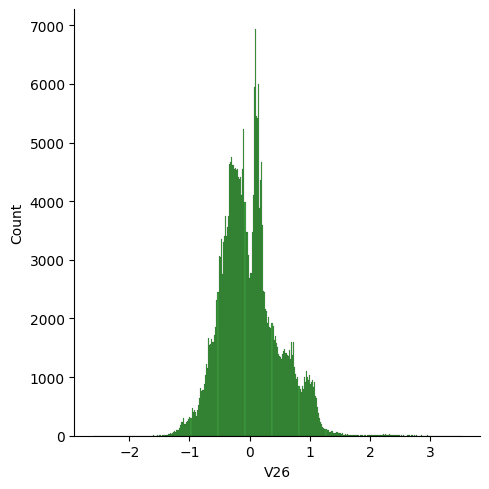

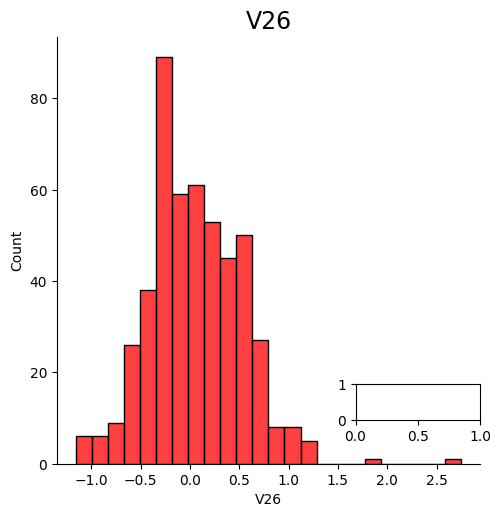

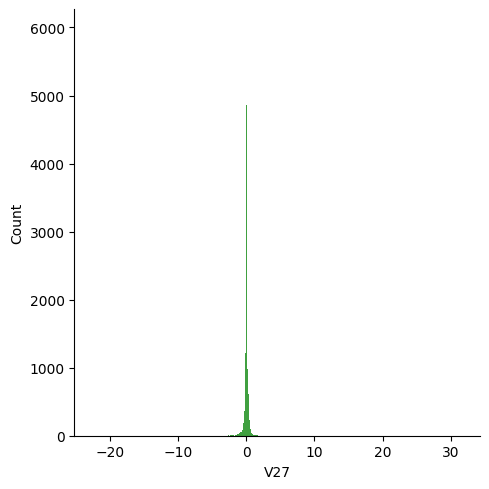

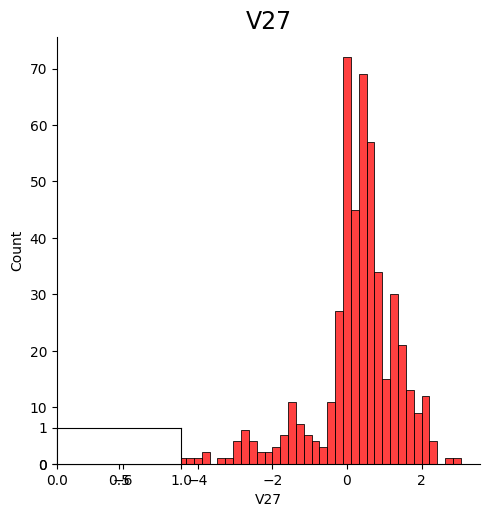

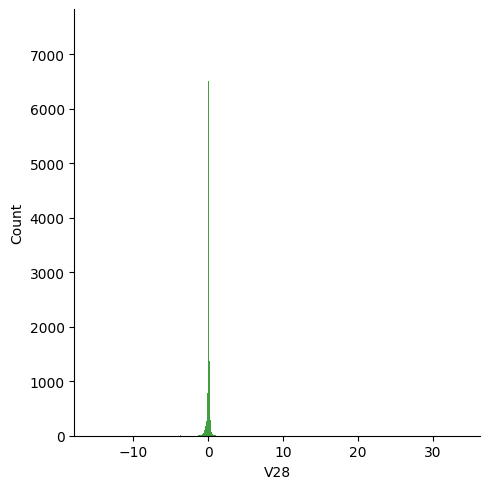

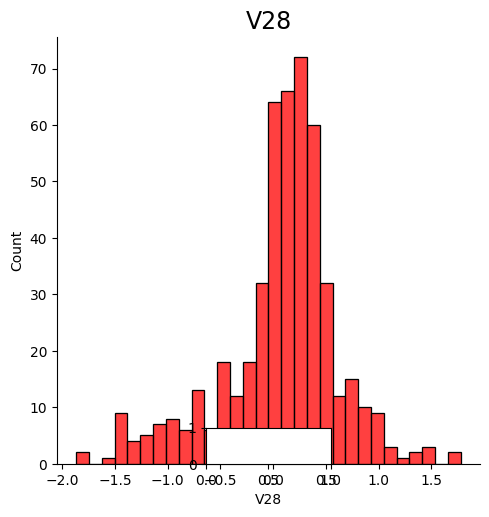

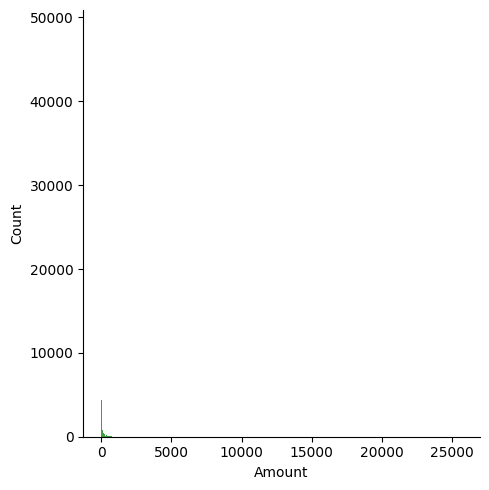

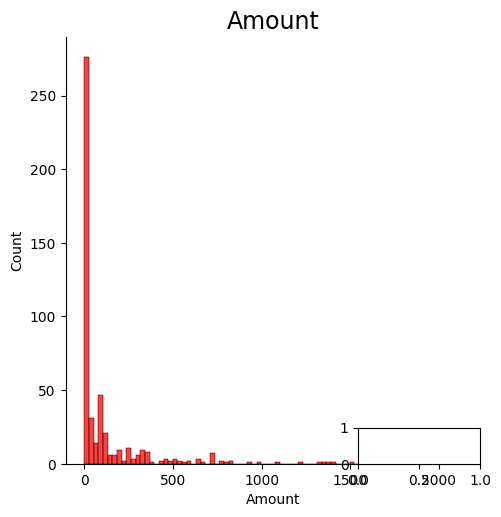

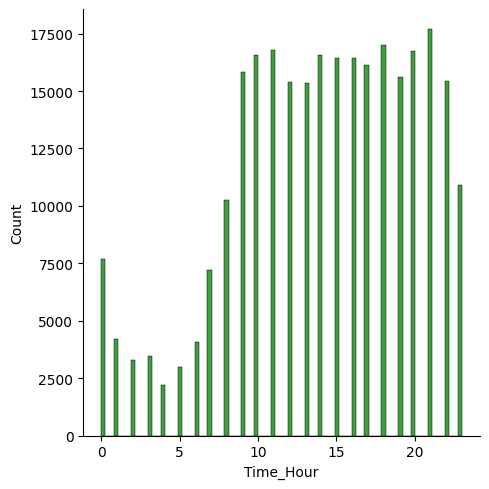

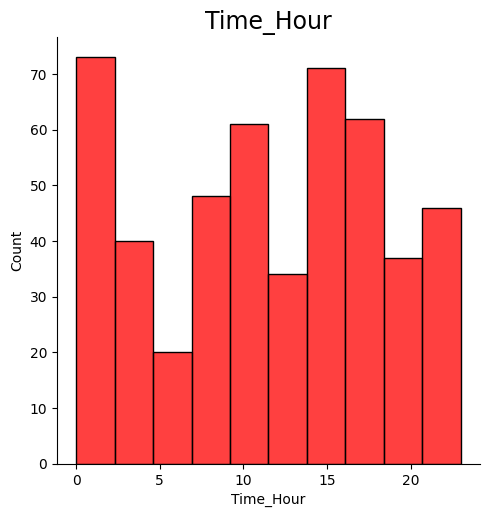

In [ ]:
normal_records=df.Class==0
fraud_record=df.Class==1

plt.figure(figsize=(20,60))
for n, col in enumerate(cols):
  plt.subplot(10,3,n+1)
  sns.displot(X[col][normal_records],color='green')
  sns.displot(X[col][fraud_record],color='red')
  plt.title(col,fontsize=17)
plt.show()

In [ ]:
df_Results=pd.DataFrame(columns=['Methodolgy','Model','Accuracy','roc_value','threshold'])

In [ ]:
# def Plot_confusion_matrix(y_test,pred_test):
#   cm=confusion_matrix(y_test,pred_test)
#   plt.clf()
#   plt.imshow(cm,interpolation='nearest',cmap=plt.cm.Accent)
#   categoryNames('Confusion Matrix-test Data')
#   plt.ylabel('True label')
#   plt.xlabel('Predicted label')
#   ticks=np.arrange(len(categoryNames))
#   plt.xticks(ticks,categoryNames,rotation=45)
#   plt.yticks(ticks,categoryNames)
#   s=[['TN','FP'],['FN','TP']]

#   for i in range(2):
#     for j in range(2):
#       plt.text(j,i,str(s[i][j])+" = "+str(cm[i][j]),fontsize=12)
#   plt.show()

from sklearn.metrics import confusion_matrix
import numpy as np
import matplotlib.pyplot as plt

def Plot_confusion_matrix(y_test, pred_test):
    # Compute confusion matrix
    cm = confusion_matrix(y_test, pred_test)

    # Class names (edit these if you have specific labels)
    categoryNames = ['Class 0', 'Class 1']   # e.g. ['Non-Fraud', 'Fraud']

    plt.figure(figsize=(6, 4))
    plt.clf()
    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Accent)
    plt.title('Confusion Matrix - Test Data')
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

    # Ticks and labels
    ticks = np.arange(len(categoryNames))
    plt.xticks(ticks, categoryNames, rotation=45)
    plt.yticks(ticks, categoryNames)

    # TN, FP, FN, TP annotations
    s = [['TN', 'FP'], ['FN', 'TP']]
    for i in range(2):
        for j in range(2):
            plt.text(j, i, f"{s[i][j]} = {cm[i][j]}", fontsize=12,
                     ha='center', va='center')

    plt.tight_layout()
    plt.show()


In [ ]:
# def buildAndRunLogisticModels(df_results,Methodology,X_train,X_test,y_train,y_test):

#   from sklearn import linear_model
#   from sklearn.model_selection import KFold

#   num_C=list(np.power(10.0,np.arange(-10,10)))
#   cv_num=KFold(n_splits=10,shuffle=True,random_state=42)

#   searchCV_12=linear_model.LogisticRegressionCV(
#       Cs=num_C,
#       penalty='l1',
#       scoring='roc_auc',
#       cv=cv_num,
#       random_state=42,
#       max_iter=10000,
#       fit_intercept=True,
#       solver='newton-cg',
#       n_jobs=-1
#   )

#   searchCV_l1=linear_model.LogisticRegressionCV(
#       Cs=num_C,
#       penalty='l1',
#       scoring='roc_auc',
#       cv=cv_num,
#       random_state=42,
#       max_iter=10000,
#       fit_intercept=True,
#       solver='liblinear',
#       tol=10
#   )

#   searchCV_l1.fit(X_train,y_train)
#   searchCV_12.fit(X_train,y_train)

#   print('Max auc_roc for l1:',searchCV_l1.scores_[1].mean(axis=0).max())
#   print('Max auc_roc for l2:',searchCV_l2.scores_[1].mean(axis=0).max())

#   print("parameters for l1 regularisations:")
#   print(searchCV_l1.coef_)
#   print(search_l1.intercept_)
#   print(searchCV_l1.scores_)

#   print("parameters for l2 regularisations:")
#   print(searchCV_l2.coef_)
#   print(search_l2.intercept_)
#   print(searchCV_l2.scores_)

#   y_pred_l1=searchCV_l1.predict(X_test)
#   y_pred_l2=searchCV_l2.predict(X_test)

#   y_pred_probs_l1=searchCV_l1.predict_proba(X_test)[:,1]
#   y_pred_probs_l2=searchCV_l2.predict_proba(X_test)[:,1]

#   Accuracy_l2=metrics.accuracy_score(y_pred=y_pred_l2,y_true=y_test)
#   Accuracy_l1=metrics.accuracy_score(y_pred=y_pred_l1,y_true=y_test)

#   print("Accuray of logistic model with l2 regularisation :{0}",format(Accuray_l2))
#   print("Confusion Matrix")
#   Plot_confusion_matrix(y_test,y_pred_l2)
#   print("classification Report")
#   print(classification_report(y_test,y_pred_l2))

#   print("Accuray of logistic model with l1 regularisation :{0}",format(Accuray_l1))
#   print("Confusion Matrix")
#   Plot_confusion_matrix(y_test,y_pred_l1)
#   print("classification Report")
#   print(classification_report(y_test,y_pred_l1))

#   l2_roc_value=roc_auc_score(y_test,y_pred_probs_l2)
#   print("l2 roc_value: {0}".format(l2_roc_value))
#   fpr,tpr,thresholds=metrics.roc_curve(y_test,y_pred_probs_l2)
#   threshold=thresholds[np.argmax(tpr-fpr)]
#   print("l2 threshold: {0}".format(threshold))

#   roc_auc=metrics.auc(fpr,tpr)
#   print("ROC for the test dataset",'{:.1%}'.format(roc_auc))
#   plt.plot(fpr,tpr,label="Test,auc="+str(roc_auc))
#   plt.legend(loc=4)
#   plt.show()

#   df_Result=df_Results.append(pd.DataFrame({'Methodology': methodology,'Model':'Logistic regression with L2 Regularisation','Accuracy':Accuracy_l2,'roc_value':l2_roc_value,'threshold':threshold},index=[0],ignore_index=True))


#   l1_roc_value=roc_auc_score(y_test,y_pred_probs_l1)
#   print("l1 roc_value: {0}".format(l1_roc_value))
#   fpr,tpr,thresholds=metrics.roc_curve(y_test,y_pred_probs_l1)
#   threshold=thresholds[np.argmax(tpr-fpr)]
#   print("l1 threshold: {0}".format(threshold))

#   roc_auc=metrics.auc(fpr,tpr)
#   print("ROC for the test dataset",'{:.1%}'.format(roc_auc))
#   plt.plot(fpr,tpr,label="Test,auc="+str(roc_auc))
#   plt.legend(loc=4)
#   plt.show()

#   df_Result=df_Results.append(pd.DataFrame({'Methodology': methodology,'Model':'Logistic regression with L1 Regularisation','Accuracy':Accuracy_l1,'roc_value':l1_roc_value,'threshold':threshold},index=[0],ignore_index=True))

#   return df_Results



# Logistic regression with L1 and L2 regularisation using LogisticRegressionCV

from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import KFold
from sklearn.metrics import classification_report, roc_auc_score
from sklearn import metrics

def buildAndRunLogisticModels(df_Results, Methodology,
                              X_train, y_train, X_test, y_test):

    # Ensure y is 1D
    y_train = np.ravel(y_train)
    y_test = np.ravel(y_test)

    # Range of C values (you can keep -10 to 10 if you want, this is just smaller)
    Cs = np.power(10.0, np.arange(-4, 4))

    # 10-fold cross-validation
    cv_num = KFold(n_splits=10, shuffle=True, random_state=42)

    # ----- L2 model -----
    logreg_l2 = LogisticRegressionCV(
        Cs=Cs,
        penalty='l2',
        scoring='roc_auc',
        cv=cv_num,
        random_state=42,
        max_iter=10000,
        fit_intercept=True,
        solver='lbfgs',      # supports L2
        n_jobs=-1
    )

    # ----- L1 model -----
    logreg_l1 = LogisticRegressionCV(
        Cs=Cs,
        penalty='l1',
        scoring='roc_auc',
        cv=cv_num,
        random_state=42,
        max_iter=10000,
        fit_intercept=True,
        solver='liblinear',  # supports L1
        n_jobs=-1
    )

    # Fit both models
    logreg_l2.fit(X_train, y_train)
    logreg_l1.fit(X_train, y_train)

    # ======================= L2 RESULTS ======================= #
    y_pred_l2 = logreg_l2.predict(X_test)
    y_pred_probs_l2 = logreg_l2.predict_proba(X_test)[:, 1]

    Accuracy_l2 = metrics.accuracy_score(y_true=y_test, y_pred=y_pred_l2)
    l2_roc_value = roc_auc_score(y_test, y_pred_probs_l2)

    print("\nAccuracy of logistic model with L2 regularisation: {0}".format(Accuracy_l2))
    print("Confusion Matrix (L2)")
    Plot_confusion_matrix(y_test, y_pred_l2)

    print("Classification Report (L2)")
    print(classification_report(y_test, y_pred_l2))

    fpr_l2, tpr_l2, thresholds_l2 = metrics.roc_curve(y_test, y_pred_probs_l2)
    threshold_l2 = thresholds_l2[np.argmax(tpr_l2 - fpr_l2)]
    roc_auc_l2 = metrics.auc(fpr_l2, tpr_l2)

    print("L2 roc_value: {0}".format(l2_roc_value))
    print("L2 threshold: {0}".format(threshold_l2))
    print("ROC (AUC) for the test dataset (L2): {0:.1%}".format(roc_auc_l2))

    plt.plot(fpr_l2, tpr_l2, label="LogReg L2, AUC={0:.3f}".format(roc_auc_l2))
    plt.legend(loc=4)
    plt.show()

    df_Results = pd.concat([
        df_Results,
        pd.DataFrame({
            'Methodology': Methodology,
            'Model': 'Logistic regression with L2 Regularisation',
            'Accuracy': Accuracy_l2,
            'roc_value': l2_roc_value,
            'threshold': threshold_l2
        }, index=[0])
    ], ignore_index=True)

    # ======================= L1 RESULTS ======================= #
    y_pred_l1 = logreg_l1.predict(X_test)
    y_pred_probs_l1 = logreg_l1.predict_proba(X_test)[:, 1]

    Accuracy_l1 = metrics.accuracy_score(y_true=y_test, y_pred=y_pred_l1)
    l1_roc_value = roc_auc_score(y_test, y_pred_probs_l1)

    print("\nAccuracy of logistic model with L1 regularisation: {0}".format(Accuracy_l1))
    print("Confusion Matrix (L1)")
    Plot_confusion_matrix(y_test, y_pred_l1)

    print("Classification Report (L1)")
    print(classification_report(y_test, y_pred_l1))

    fpr_l1, tpr_l1, thresholds_l1 = metrics.roc_curve(y_test, y_pred_probs_l1)
    threshold_l1 = thresholds_l1[np.argmax(tpr_l1 - fpr_l1)]
    roc_auc_l1 = metrics.auc(fpr_l1, tpr_l1)

    print("L1 roc_value: {0}".format(l1_roc_value))
    print("L1 threshold: {0}".format(threshold_l1))
    print("ROC (AUC) for the test dataset (L1): {0:.1%}".format(roc_auc_l1))

    plt.plot(fpr_l1, tpr_l1, label="LogReg L1, AUC={0:.3f}".format(roc_auc_l1))
    plt.legend(loc=4)
    plt.show()

    df_Results = pd.concat([
        df_Results,
        pd.DataFrame({
            'Methodology': Methodology,
            'Model': 'Logistic regression with L1 Regularisation',
            'Accuracy': Accuracy_l1,
            'roc_value': l1_roc_value,
            'threshold': threshold_l1
        }, index=[0])
    ], ignore_index=True)

    return df_Results



In [ ]:
# from sklearn.neighbors import KNeighborsClassifier
# from sklearn.metrics import classification_report, roc_auc_score
# from sklearn import metrics

# def buildAndRunKNNModels(df_Results, Methodology,
#                          X_train, X_test, y_train, y_test):

#     # Build and train model
#     knn = KNeighborsClassifier(n_neighbors=5, n_jobs=16)
#     knn.fit(X_train, y_train)

#     # Accuracy on test set
#     score = knn.score(X_test, y_test)
#     print("KNN model score (test accuracy):", score)

#     # Predictions
#     y_pred = knn.predict(X_test)
#     KNN_Accuracy = metrics.accuracy_score(y_true=y_test, y_pred=y_pred)

#     print("Confusion matrix")
#     Plot_confusion_matrix(y_test, y_pred)

#     print("Classification Report")
#     print(classification_report(y_test, y_pred))

#     # ROC / AUC
#     knn_probs = knn.predict_proba(X_test)[:, 1]
#     knn_roc_value = roc_auc_score(y_test, knn_probs)
#     print("KNN roc_value: {0}".format(knn_roc_value))

#     fpr, tpr, thresholds = metrics.roc_curve(y_test, knn_probs)
#     threshold = thresholds[np.argmax(tpr - fpr)]
#     print("KNN threshold: {0}".format(threshold))

#     roc_auc = metrics.auc(fpr, tpr)
#     print("ROC for the test dataset:", '{:.1%}'.format(roc_auc))

#     plt.plot(fpr, tpr, label="KNN Test, AUC=" + str(roc_auc))
#     plt.legend(loc=4)
#     plt.show()

#     # Store results in df_Results
#     df_Results = pd.concat([
#         df_Results,
#         pd.DataFrame({
#             'Methodology': Methodology,
#             'Model': 'KNN',
#             'Accuracy': score,
#             'roc_value': knn_roc_value,
#             'threshold': threshold
#         }, index=[0])
#     ], ignore_index=True)

#     return df_Results


from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, roc_auc_score
from sklearn import metrics

def buildAndRunKNNModels(df_Results, Methodology,
                         X_train, y_train, X_test, y_test):

    # Ensure y is 1D
    y_train = np.ravel(y_train)
    y_test = np.ravel(y_test)

    # Build and train model
    knn = KNeighborsClassifier(n_neighbors=5, n_jobs=16)
    knn.fit(X_train, y_train)

    # Accuracy on test set
    score = knn.score(X_test, y_test)
    print("KNN model score (test accuracy):", score)

    # Predictions
    y_pred = knn.predict(X_test)
    KNN_Accuracy = metrics.accuracy_score(y_true=y_test, y_pred=y_pred)

    print("Confusion matrix (KNN)")
    Plot_confusion_matrix(y_test, y_pred)

    print("Classification Report (KNN)")
    print(classification_report(y_test, y_pred))

    # ROC / AUC
    knn_probs = knn.predict_proba(X_test)[:, 1]
    knn_roc_value = roc_auc_score(y_test, knn_probs)
    print("KNN roc_value: {0}".format(knn_roc_value))

    fpr, tpr, thresholds = metrics.roc_curve(y_test, knn_probs)
    threshold = thresholds[np.argmax(tpr - fpr)]
    print("KNN threshold: {0}".format(threshold))

    roc_auc = metrics.auc(fpr, tpr)
    print("ROC for the test dataset (KNN):", '{:.1%}'.format(roc_auc))

    plt.plot(fpr, tpr, label="KNN Test, AUC=" + str(roc_auc))
    plt.legend(loc=4)
    plt.show()

    # Store results in df_Results
    df_Results = pd.concat([
        df_Results,
        pd.DataFrame({
            'Methodology': Methodology,
            'Model': 'KNN',
            'Accuracy': score,
            'roc_value': knn_roc_value,
            'threshold': threshold
        }, index=[0])
    ], ignore_index=True)

    return df_Results


In [ ]:
# def builtAndRunTreeModels(df_Results, Methodology,
#                           X_train, X_test, y_train, y_test):

#     criteria = ['gini', 'entropy']

#     for c in criteria:
#         dt = DecisionTreeClassifier(criterion=c, random_state=42)
#         dt.fit(X_train, y_train)

#         # Predictions
#         y_pred = dt.predict(X_test)
#         test_score = dt.score(X_test, y_test)
#         tree_preds = dt.predict_proba(X_test)[:, 1]
#         tree_roc_value = roc_auc_score(y_test, tree_preds)

#         print(c + " score: {0}".format(test_score))
#         print("Confusion Matrix")
#         Plot_confusion_matrix(y_test, y_pred)

#         print("Classification Report")
#         print(classification_report(y_test, y_pred))

#         print(c + " tree_roc_value: {0}".format(tree_roc_value))

#         # ROC curve
#         fpr, tpr, thresholds = metrics.roc_curve(y_test, tree_preds)
#         threshold = thresholds[np.argmax(tpr - fpr)]
#         print("Tree threshold: {0}".format(threshold))

#         roc_auc = metrics.auc(fpr, tpr)
#         print("ROC for the test dataset:", '{:.1%}'.format(roc_auc))

#         plt.plot(fpr, tpr, label="Test, AUC=" + str(roc_auc))
#         plt.legend(loc=4)
#         plt.show()

#         # Append results correctly
#         df_Results = pd.concat([
#             df_Results,
#             pd.DataFrame({
#                 'Methodology': Methodology,
#                 'Model': f'Tree Model with {c} criterion',
#                 'Accuracy': test_score,
#                 'roc_value': tree_roc_value,
#                 'threshold': threshold
#             }, index=[0])
#         ], ignore_index=True)

#     return df_Results



from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, roc_auc_score
from sklearn import metrics

def builtAndRunTreeModels(df_Results, Methodology,
                          X_train, y_train, X_test, y_test):

    # Ensure y is 1D
    y_train = np.ravel(y_train)
    y_test = np.ravel(y_test)

    criteria = ['gini', 'entropy']

    for c in criteria:
        print(f"\nDecision Tree with criterion = {c}")

        dt = DecisionTreeClassifier(criterion=c, random_state=42)
        dt.fit(X_train, y_train)

        # Predictions
        y_pred = dt.predict(X_test)
        test_score = dt.score(X_test, y_test)
        tree_probs = dt.predict_proba(X_test)[:, 1]
        tree_roc_value = roc_auc_score(y_test, tree_probs)

        print(f"{c} score: {test_score}")
        print("Confusion Matrix")
        Plot_confusion_matrix(y_test, y_pred)

        print("Classification Report")
        print(classification_report(y_test, y_pred))

        print(f"{c} tree_roc_value: {tree_roc_value}")

        # ROC curve and threshold
        fpr, tpr, thresholds = metrics.roc_curve(y_test, tree_probs)
        threshold = thresholds[np.argmax(tpr - fpr)]
        print("Tree threshold: {0}".format(threshold))

        roc_auc = metrics.auc(fpr, tpr)
        print("ROC for the test dataset:", "{:.1%}".format(roc_auc))

        plt.plot(fpr, tpr, label=f"DT ({c}) Test, AUC={roc_auc:.3f}")
        plt.legend(loc=4)
        plt.show()

        # Save results
        df_Results = pd.concat([
            df_Results,
            pd.DataFrame({
                'Methodology': Methodology,
                'Model': f'Decision Tree ({c})',
                'Accuracy': test_score,
                'roc_value': tree_roc_value,
                'threshold': threshold
            }, index=[0])
        ], ignore_index=True)

    return df_Results


In [ ]:
# def buildAndRunRandomForestModels(df_Results,Methodology,X_train,X_test,y_train,y_test):

#   RF_model=RandomForestClassifier(n_estimators=100,bootstrap=True,max_features='sqrt',random_state=42)
#   RF_model.fit(X_train,y_train)
#   RF_test_score=RF_model.score(X_test,y_test)
#   RF_model.predict(X_test)
#   print('Model Accuracy: {0}'.format(RF_test_score))

#   rf_predictions=RF_model.predict(X_test)

#   print("Confusion Matrix")
#   Plot_confusion_matrix(y_test,rf_predictions)
#   print("classification Report")
#   print(classification_report(y_test,rf_predictions))
#   rf_probs=RF_model.predict_proba(X_test)[:,1]
#   roc_value=roc_auc_score(y_test,rf_probs)

#   print("Random Forest roc_value :{0}".format(roc_value))
#   fpr,tpr,thresholds=metrics.roc_curve(y_test,rf_probs)
#   threshold=thresholds[np.argmax(tpr-fpr)]
#   print("Random Forest threshold:{0}".format(threshold))
#   roc_auc=metrics.auc(fpr,tpr)
#   print("Roc for  the test dataset",'{:.1%}'.format(roc_auc))
#   plt.plot(fpr,tpr,label="Test,auc="+str(roc_auc))
#   plt.legend(loc=4)
#   plt.show()
#   df_Results=df_Results.append(pd.DataFrame({'Methodology': Methodology,'Model':'Random Forest','Accuracy':RF_test_score,'roc_value':roc_value,'threshold':threshold},index=[0],ignore_index=True))

#   return df_Results


from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score
from sklearn import metrics

def buildAndRunRandomForestModels(df_Results, Methodology,
                                  X_train, y_train, X_test, y_test):

    # Ensure y is 1D
    y_train = np.ravel(y_train)
    y_test = np.ravel(y_test)

    # Build and train model
    RF_model = RandomForestClassifier(
        n_estimators=100,
        bootstrap=True,
        max_features='sqrt',
        random_state=42,
        n_jobs=-1
    )
    RF_model.fit(X_train, y_train)

    # Accuracy on test set
    RF_test_score = RF_model.score(X_test, y_test)
    print('Random Forest - Model Accuracy: {0}'.format(RF_test_score))

    # Predictions
    rf_predictions = RF_model.predict(X_test)

    print("Confusion Matrix (Random Forest)")
    Plot_confusion_matrix(y_test, rf_predictions)

    print("Classification Report (Random Forest)")
    print(classification_report(y_test, rf_predictions))

    # Probabilities for ROC
    rf_probs = RF_model.predict_proba(X_test)[:, 1]
    roc_value = roc_auc_score(y_test, rf_probs)

    print("Random Forest roc_value: {0}".format(roc_value))

    fpr, tpr, thresholds = metrics.roc_curve(y_test, rf_probs)
    threshold = thresholds[np.argmax(tpr - fpr)]
    print("Random Forest threshold: {0}".format(threshold))

    roc_auc = metrics.auc(fpr, tpr)
    print("ROC for the test dataset (Random Forest):", '{:.1%}'.format(roc_auc))

    plt.plot(fpr, tpr, label="Random Forest Test, AUC=" + str(roc_auc))
    plt.legend(loc=4)
    plt.show()

    # Store results (use concat instead of deprecated append)
    df_Results = pd.concat([
        df_Results,
        pd.DataFrame({
            'Methodology': Methodology,
            'Model': 'Random Forest',
            'Accuracy': RF_test_score,
            'roc_value': roc_value,
            'threshold': threshold
        }, index=[0])
    ], ignore_index=True)

    return df_Results



In [ ]:
# def buildAndRunXGBoostModels(df_Results,Methodology,X_train,X_test,y_train,y_test):
#   XGBmodel=XGBClassifier(random_state=42)
#   XGBmodel.fit(X_train,y_train)
#   y_pred=XGBmodel.predict(X_test)

#   XGB_test_score=XGBmodel.score(X_test,y_test)
#   print('Model Accuracy: {0}'.format(XGB_test_score))

#   print("Confusion Matrix")
#   Plot_confusion_matrix(y_test,y_pred)
#   print("classification Report")
#   print(classification_report(y_test,y_pred))
#   XGB_probs=XGBmodel.predict_proba(X_test)[:,1]
#   XGB_roc_value=roc_auc_score(y_test,XGB_probs)

#   print("XGBoost roc_value :{0}".format(XGB_roc_value))
#   fpr,tpr,thresholds=metrics.roc_curve(y_test,XGB_probs)
#   threshold=thresholds[np.argmax(tpr-fpr)]
#   print("XGBoost threshold:{0}".format(threshold))
#   roc_auc=metrics.auc(fpr,tpr)
#   print("ROC for the test dataset",'{:.1%}'.format(roc_auc))
#   plt.plot(fpr,tpr,label="Test,auc="+str(roc_auc))
#   plt.legen(loc=4)
#   plt.show()

#   df_Results=df_Results.append(pd.DataFrame({'Methodology': Methodology,'Model':'XGBoost','Accuracy':XGB_test_score,'roc_value':XGB_roc_value,'threshold':threshold},index=[0],ignore_index=True))

#   return df_Results


from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score
from sklearn import metrics

def buildAndRunXGBoostModels(df_Results, Methodology,
                             X_train, y_train, X_test, y_test):

    # Ensure y is 1D
    y_train = np.ravel(y_train)
    y_test = np.ravel(y_test)

    # Build XGBoost model (binary classification)
    XGBmodel = XGBClassifier(
        random_state=42,
        objective='binary:logistic',
        eval_metric='logloss',
        n_estimators=200,
        n_jobs=-1
    )

    # Train
    XGBmodel.fit(X_train, y_train)

    # Predict
    y_pred = XGBmodel.predict(X_test)
    XGB_test_score = XGBmodel.score(X_test, y_test)
    print('XGBoost - Model Accuracy: {0}'.format(XGB_test_score))

    # Confusion matrix and report
    print("Confusion Matrix (XGBoost)")
    Plot_confusion_matrix(y_test, y_pred)

    print("Classification Report (XGBoost)")
    print(classification_report(y_test, y_pred))

    # Probabilities for ROC
    XGB_probs = XGBmodel.predict_proba(X_test)[:, 1]
    XGB_roc_value = roc_auc_score(y_test, XGB_probs)

    print("XGBoost roc_value: {0}".format(XGB_roc_value))
    fpr, tpr, thresholds = metrics.roc_curve(y_test, XGB_probs)
    threshold = thresholds[np.argmax(tpr - fpr)]
    print("XGBoost threshold: {0}".format(threshold))

    roc_auc = metrics.auc(fpr, tpr)
    print("ROC for the test dataset (XGBoost):", '{:.1%}'.format(roc_auc))

    plt.plot(fpr, tpr, label="XGBoost Test, AUC=" + str(roc_auc))
    plt.legend(loc=4)
    plt.show()

    # Store results (use concat instead of append)
    df_Results = pd.concat([
        df_Results,
        pd.DataFrame({
            'Methodology': Methodology,
            'Model': 'XGBoost',
            'Accuracy': XGB_test_score,
            'roc_value': XGB_roc_value,
            'threshold': threshold
        }, index=[0])
    ], ignore_index=True)

    return df_Results


In [ ]:
# def buildAndRunSVMModels(df_Results,Methodology,X_train,y_train,X_test,y_test):
#   from sklearn.svm import SVC
#   from sklearn.metrics import accuracy_score
#   from sklearn.metrics import roc_auc_score

#   clf=SVC(kernel='sigmoid',random_state=42)
#   clf.fit(X_train,y_train)
#   y_predict_SVM=clf.predict(X_test)
#   SVM_Score=accuracy_score(y_test,y_pred_SVM)
#   print("accuracy_score :{0}".format(SVM_Score))
#   print("Confusion Matrix")
#   Plot_confusion_matrix(y_test,y_pred_SVM)
#   print("classification Report")
#   print(classification_report(y_test,y_pred_SVM))

#   classifier=SVC(kernel='sigmoid',probability=True)
#   svm_probs=classifier.fit(X_train,y_train).predict_proba(X_test)[:,1]

#   roc_value=roc_auc_score(y_test,svm_probs)

#   print("SVM roc_value :{0}".format(roc_value))
#   fpr,tpr,threshold=metrics.roc_curve(y_test,svm_probs)
#   threshold=thresholds[np.argmax(tpr-fpr)]
#   print("SVM threshold: {0}".format(threshold))
#   roc_auc=metrics.auc(fpr,tpr)
#   print("ROC for the test dataset",'{:.1%}'.format(roc_auc))
#   plt.plot(fpr,tpr,label="Test,auc="+str(roc_auc))
#   plt.legend(loc=4)
#   plt.show()

#   df_Results=df_Results.append(pd.DataFrame({'Methodology': Methodology,'Model':'SVM','Accuracy':SVM_Score,'roc_value':roc_value,'threshold':threshold},index=[0],ignore_index=True))

#   return df_Results


from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score
from sklearn import metrics

def buildAndRunSVMModels(df_Results, Methodology,
                         X_train, y_train, X_test, y_test):

    # Ensure y is 1D
    y_train = np.ravel(y_train)
    y_test = np.ravel(y_test)

    # SVM with sigmoid kernel and probability enabled
    clf = SVC(kernel='sigmoid', probability=True, random_state=42)
    clf.fit(X_train, y_train)

    # Predictions (class labels)
    y_pred_SVM = clf.predict(X_test)

    # Accuracy
    SVM_Score = accuracy_score(y_test, y_pred_SVM)
    print("SVM accuracy_score: {0}".format(SVM_Score))

    print("Confusion Matrix (SVM)")
    Plot_confusion_matrix(y_test, y_pred_SVM)

    print("Classification Report (SVM)")
    print(classification_report(y_test, y_pred_SVM))

    # Probabilities for ROC
    svm_probs = clf.predict_proba(X_test)[:, 1]
    roc_value = roc_auc_score(y_test, svm_probs)

    print("SVM roc_value: {0}".format(roc_value))

    fpr, tpr, thresholds = metrics.roc_curve(y_test, svm_probs)
    threshold = thresholds[np.argmax(tpr - fpr)]
    print("SVM threshold: {0}".format(threshold))

    roc_auc = metrics.auc(fpr, tpr)
    print("ROC for the test dataset (SVM):", '{:.1%}'.format(roc_auc))

    plt.plot(fpr, tpr, label="SVM Test, AUC=" + str(roc_auc))
    plt.legend(loc=4)
    plt.show()

    # Store results using concat instead of deprecated append
    df_Results = pd.concat([
        df_Results,
        pd.DataFrame({
            'Methodology': Methodology,
            'Model': 'SVM',
            'Accuracy': SVM_Score,
            'roc_value': roc_value,
            'threshold': threshold
        }, index=[0])
    ], ignore_index=True)

    return df_Results



In [ ]:
# from sklearn.model_selection import RepeatedKFold
# rkf=RepeatedKFold(n_splits=5,n_repeats=10,random_state=None)
# for train_index,test_index in rkf.split(X,y):
#   print("TRAIN:",train_index,"TEST:",test_index)
#   X_train_cv,X_test_CV=X.iloc[train_index],X.iloc[test_index]
#   y_train_cv,y_test_cv=y.iloc[train_index],y.iloc[test_index]
from sklearn.model_selection import RepeatedKFold

rkf = RepeatedKFold(n_splits=5, n_repeats=10, random_state=None)

for train_index, test_index in rkf.split(X, y):
    print("TRAIN:", train_index, "TEST:", test_index)

    X_train_cv, X_test_cv = X.iloc[train_index], X.iloc[test_index]
    y_train_cv, y_test_cv = y.iloc[train_index], y.iloc[test_index]


TRAIN: [     0      2      3 ... 284804 284805 284806] TEST: [     1     12     19 ... 284787 284797 284800]
TRAIN: [     1      2      3 ... 284802 284804 284805] TEST: [     0      5      6 ... 284795 284803 284806]
TRAIN: [     0      1      2 ... 284803 284805 284806] TEST: [     4     11     25 ... 284796 284798 284804]
TRAIN: [     0      1      2 ... 284803 284804 284806] TEST: [     7      9     17 ... 284793 284801 284805]
TRAIN: [     0      1      4 ... 284804 284805 284806] TEST: [     2      3      8 ... 284792 284799 284802]
TRAIN: [     0      1      4 ... 284803 284805 284806] TEST: [     2      3      7 ... 284795 284800 284804]
TRAIN: [     1      2      3 ... 284802 284803 284804] TEST: [     0      8     10 ... 284801 284805 284806]
TRAIN: [     0      1      2 ... 284804 284805 284806] TEST: [     4     12     13 ... 284799 284802 284803]
TRAIN: [     0      2      3 ... 284804 284805 284806] TEST: [     1      5      6 ... 284791 284796 284797]
TRAIN: [     0     

Logistic rzegression with L1 and L2 regularisation

Accuracy of logistic model with L2 regularisation: 0.9989817594494479
Confusion Matrix (L2)


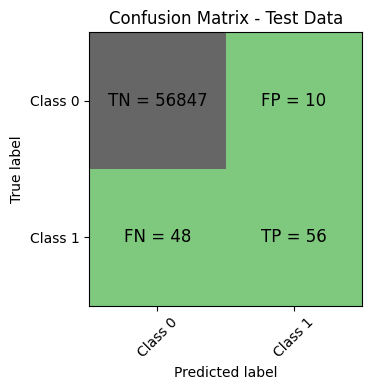

Classification Report (L2)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56857
           1       0.85      0.54      0.66       104

    accuracy                           1.00     56961
   macro avg       0.92      0.77      0.83     56961
weighted avg       1.00      1.00      1.00     56961

L2 roc_value: 0.9860593242696589
L2 threshold: 0.001815091682720626
ROC (AUC) for the test dataset (L2): 98.6%


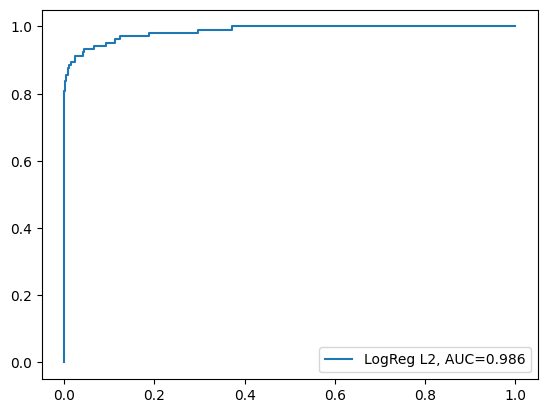


Accuracy of logistic model with L1 regularisation: 0.9991748740366215
Confusion Matrix (L1)


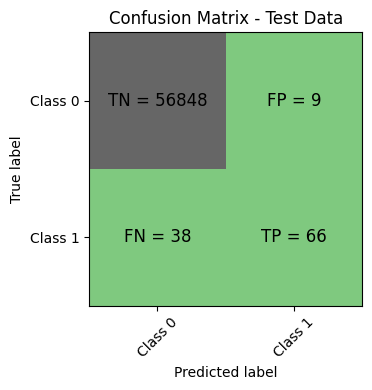

Classification Report (L1)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56857
           1       0.88      0.63      0.74       104

    accuracy                           1.00     56961
   macro avg       0.94      0.82      0.87     56961
weighted avg       1.00      1.00      1.00     56961

L1 roc_value: 0.9753737784806958
L1 threshold: 0.0029641269167341427
ROC (AUC) for the test dataset (L1): 97.5%


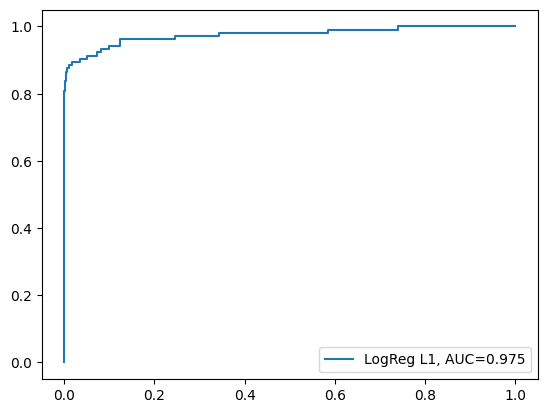

Time Taken by Model:-----264.1900010108948 second----
------------------------------------------------------------
KNN Model
KNN model score (test accuracy): 0.9992099857797441
Confusion matrix (KNN)


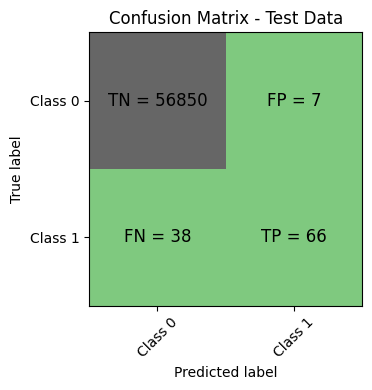

Classification Report (KNN)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56857
           1       0.90      0.63      0.75       104

    accuracy                           1.00     56961
   macro avg       0.95      0.82      0.87     56961
weighted avg       1.00      1.00      1.00     56961

KNN roc_value: 0.8892112600978703
KNN threshold: 0.2
ROC for the test dataset (KNN): 88.9%


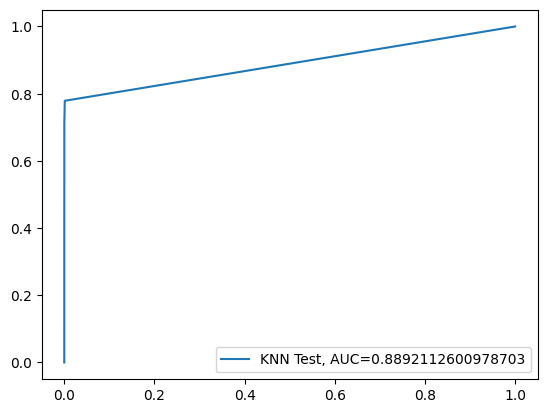

Time Taken by Model:-----176.80264019966125 second----
------------------------------------------------------------
Decision Tree Models with  'gini' & 'entropy' criteria

Decision Tree with criterion = gini
gini score: 0.9992626533944278
Confusion Matrix


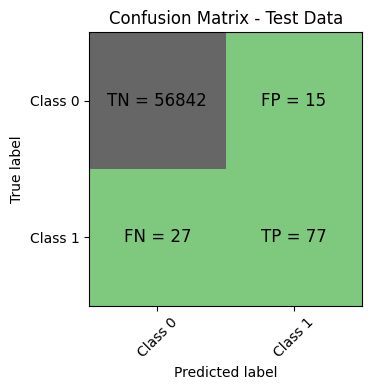

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56857
           1       0.84      0.74      0.79       104

    accuracy                           1.00     56961
   macro avg       0.92      0.87      0.89     56961
weighted avg       1.00      1.00      1.00     56961

gini tree_roc_value: 0.8700603978131372
Tree threshold: 1.0
ROC for the test dataset: 87.0%


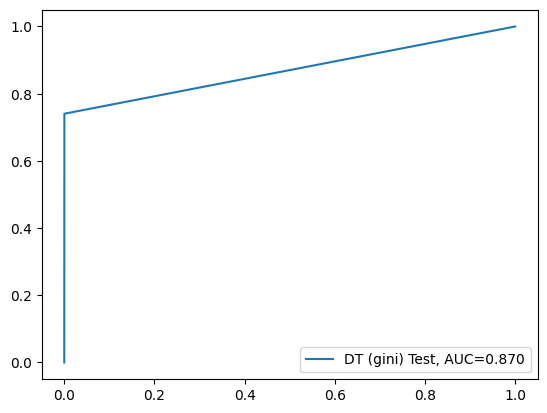


Decision Tree with criterion = entropy
entropy score: 0.9990870946788153
Confusion Matrix


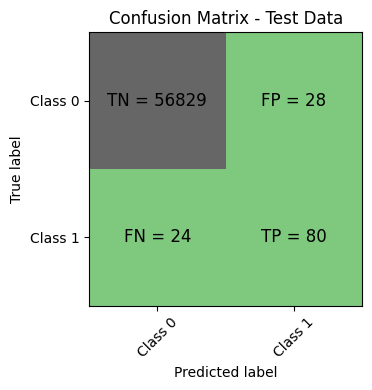

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56857
           1       0.74      0.77      0.75       104

    accuracy                           1.00     56961
   macro avg       0.87      0.88      0.88     56961
weighted avg       1.00      1.00      1.00     56961

entropy tree_roc_value: 0.8843691528409329
Tree threshold: 1.0
ROC for the test dataset: 88.4%


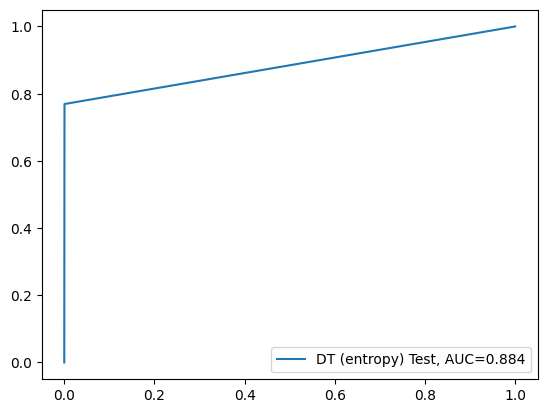

Time Taken by Model:-----38.832584857940674 second----
------------------------------------------------------------
Rondom Forest Model
Random Forest - Model Accuracy: 0.999490879724724
Confusion Matrix (Random Forest)


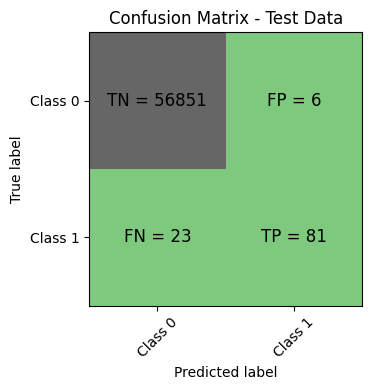

Classification Report (Random Forest)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56857
           1       0.93      0.78      0.85       104

    accuracy                           1.00     56961
   macro avg       0.97      0.89      0.92     56961
weighted avg       1.00      1.00      1.00     56961

Random Forest roc_value: 0.9356532616916123
Random Forest threshold: 0.01
ROC for the test dataset (Random Forest): 93.6%


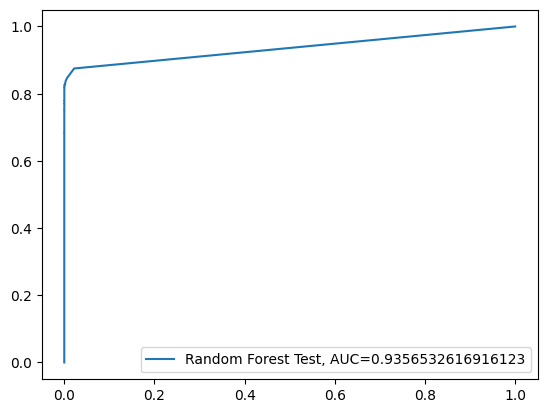

Time Taken by Model:-----213.77431774139404 second----
------------------------------------------------------------
XGBoost Model
XGBoost - Model Accuracy: 0.9991046505503766
Confusion Matrix (XGBoost)


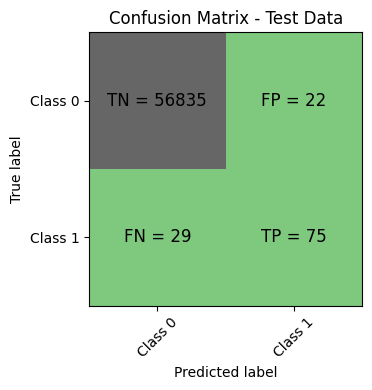

Classification Report (XGBoost)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56857
           1       0.77      0.72      0.75       104

    accuracy                           1.00     56961
   macro avg       0.89      0.86      0.87     56961
weighted avg       1.00      1.00      1.00     56961

XGBoost roc_value: 0.905950200976539
XGBoost threshold: 6.431900146708358e-06
ROC for the test dataset (XGBoost): 90.6%


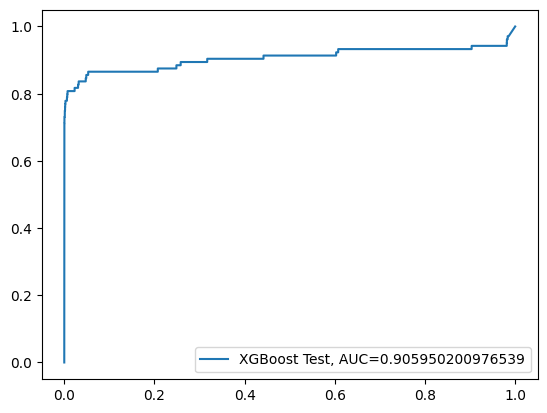

Time Taken by Model:-----6.802077770233154 second----
------------------------------------------------------------
SVM Model
SVM accuracy_score: 0.9982619687154369
Confusion Matrix (SVM)


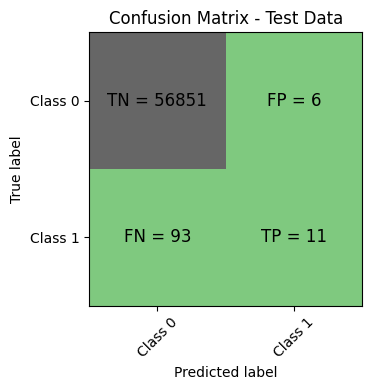

Classification Report (SVM)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56857
           1       0.65      0.11      0.18       104

    accuracy                           1.00     56961
   macro avg       0.82      0.55      0.59     56961
weighted avg       1.00      1.00      1.00     56961

SVM roc_value: 0.5467948605205231
SVM threshold: 0.001796935221501312
ROC for the test dataset (SVM): 54.7%


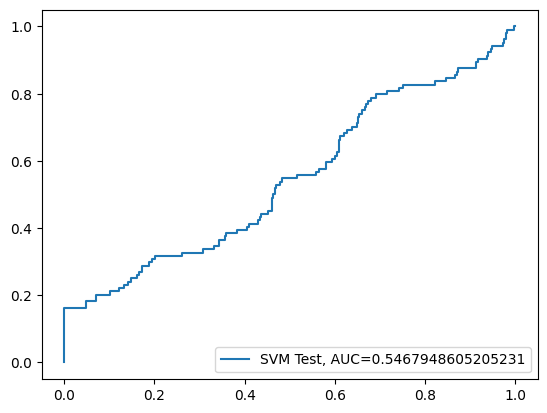

Time Taken by Model:-----574.4704596996307 second----


In [ ]:
print("Logistic rzegression with L1 and L2 regularisation")
start_time=time.time()
df_Results=buildAndRunLogisticModels(df_Results,"RepeatedKFold Cross validatio",X_train_cv,y_train_cv,X_test_cv,y_test_cv)
print("Time Taken by Model:-----%s second----"% (time.time()-start_time))
print('-'*60)

print("KNN Model")
start_time=time.time()
df_Results=buildAndRunKNNModels(df_Results,"RepeatedKFold Cross Validation",X_train_cv,y_train_cv,X_test_cv,y_test_cv)
print("Time Taken by Model:-----%s second----"% (time.time()-start_time))
print('-'*60)

print("Decision Tree Models with  'gini' & 'entropy' criteria")
start_time=time.time()
df_Results=builtAndRunTreeModels(df_Results,"RepeatedKFold Cross Validation",X_train_cv,y_train_cv,X_test_cv,y_test_cv)
print("Time Taken by Model:-----%s second----"% (time.time()-start_time))
print('-'*60)

print("Rondom Forest Model")
start_time=time.time()
df_Results=buildAndRunRandomForestModels(df_Results,"RepeatedKFold Cross Validation",X_train_cv,y_train_cv,X_test_cv,y_test_cv)
print("Time Taken by Model:-----%s second----"% (time.time()-start_time))
print('-'*60)

print("XGBoost Model")
start_time=time.time()
df_Results=buildAndRunXGBoostModels(df_Results,"RepeatedKFold Cross Validation",X_train_cv,y_train_cv,X_test_cv,y_test_cv)
print("Time Taken by Model:-----%s second----"% (time.time()-start_time))
print('-'*60)

print("SVM Model")
start_time=time.time()
df_Results=buildAndRunSVMModels(df_Results,"RepeatedKFold Cross Validation",X_train_cv,y_train_cv,X_test_cv,y_test_cv)
print("Time Taken by Model:-----%s second----"% (time.time()-start_time))


In [ ]:
df_Results

,Methodolgy,Model,Accuracy,roc_value,threshold,Methodology
0,NaN,Logistic regression with L2 Regularisation,0.998982,0.986059,0.001815,RepeatedKFold Cross validatio
1,NaN,Logistic regression with L1 Regularisation,0.999175,0.975374,0.002964,RepeatedKFold Cross validatio
2,NaN,KNN,0.999210,0.889211,0.200000,RepeatedKFold Cross Validation
3,NaN,Decision Tree (gini),0.999263,0.870060,1.000000,RepeatedKFold Cross Validation
4,NaN,Decision Tree (entropy),0.999087,0.884369,1.000000,RepeatedKFold Cross Validation
5,NaN,Random Forest,0.999491,0.935653,0.010000,RepeatedKFold Cross Validation
6,NaN,XGBoost,0.999105,0.905950,0.000006,RepeatedKFold Cross Validation
7,NaN,SVM,0.998262,0.546795,0.001797,RepeatedKFold Cross Validation


In [ ]:
# from sklearn.model_selection import StratifiedKFold
# skf=StratifiedKFold(n_splits=5,random_state=None)
# for train_index,test_index in skf.split(X,y):
#   print("TRAIN:",train_index,"TEST:",test_index)
#   X_train_SKF_cv,X_test_SKF_cv=X.iloc[train_index],X.iloc[test_index]
#   X_train_SKF_cv,y_test_SKF_cv=y.iloc[train_index],y.iloc[test_index]
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for train_index, test_index in skf.split(X, y):
    print("TRAIN:", train_index, "TEST:", test_index)

    X_train_SKF_cv, X_test_SKF_cv = X.iloc[train_index], X.iloc[test_index]
    y_train_SKF_cv, y_test_SKF_cv = y.iloc[train_index], y.iloc[test_index]


TRAIN: [     0      1      2 ... 284804 284805 284806] TEST: [     5      7      9 ... 284778 284793 284799]
TRAIN: [     0      3      4 ... 284804 284805 284806] TEST: [     1      2     13 ... 284792 284797 284801]
TRAIN: [     1      2      5 ... 284800 284801 284803] TEST: [     0      3      4 ... 284804 284805 284806]
TRAIN: [     0      1      2 ... 284804 284805 284806] TEST: [    14     19     27 ... 284795 284796 284800]
TRAIN: [     0      1      2 ... 284804 284805 284806] TEST: [    11     15     22 ... 284791 284794 284803]


Logistic Regression with L1 And L2 Regularisation

Accuracy of logistic model with L2 regularisation: 0.9990870946788153
Confusion Matrix (L2)


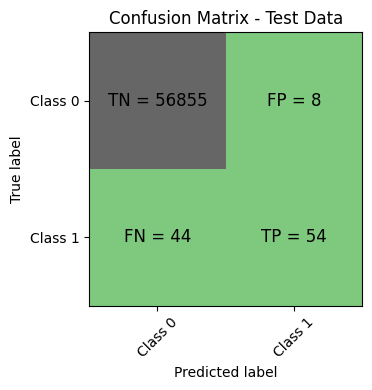

Classification Report (L2)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.87      0.55      0.68        98

    accuracy                           1.00     56961
   macro avg       0.94      0.78      0.84     56961
weighted avg       1.00      1.00      1.00     56961

L2 roc_value: 0.982690943179938
L2 threshold: 0.001845665795663997
ROC (AUC) for the test dataset (L2): 98.3%


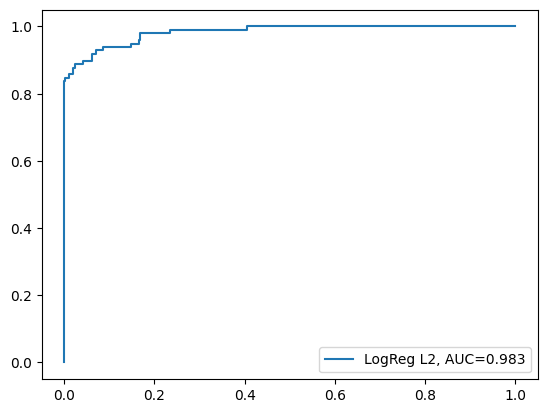


Accuracy of logistic model with L1 regularisation: 0.9992626533944278
Confusion Matrix (L1)


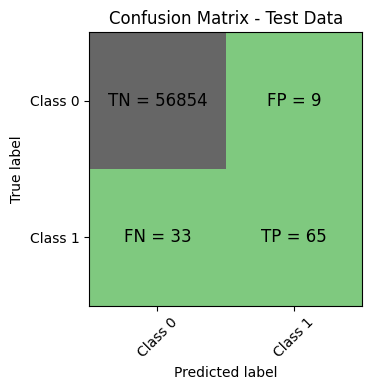

Classification Report (L1)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.88      0.66      0.76        98

    accuracy                           1.00     56961
   macro avg       0.94      0.83      0.88     56961
weighted avg       1.00      1.00      1.00     56961

L1 roc_value: 0.9695664875872443
L1 threshold: 0.002156883635152652
ROC (AUC) for the test dataset (L1): 97.0%


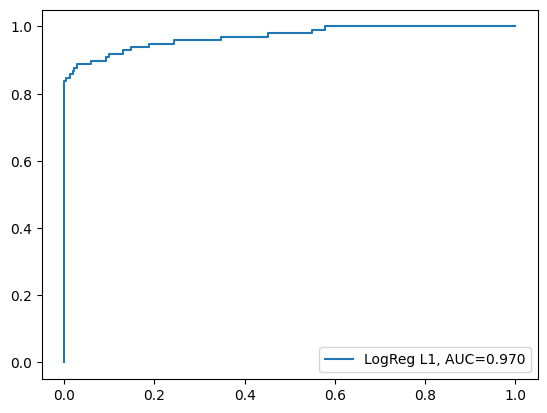

Time Taken by Model: --349.8836991786957 seconds---
------------------------------------------------------------
KNN Model
KNN model score (test accuracy): 0.9991397622934991
Confusion matrix (KNN)


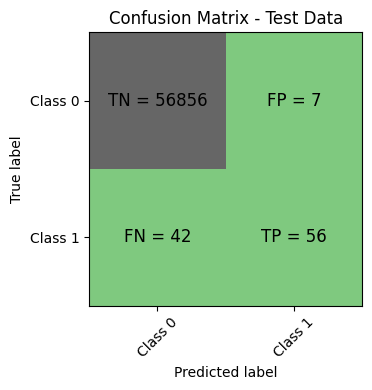

Classification Report (KNN)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.89      0.57      0.70        98

    accuracy                           1.00     56961
   macro avg       0.94      0.79      0.85     56961
weighted avg       1.00      1.00      1.00     56961

KNN roc_value: 0.8773440245028599
KNN threshold: 0.2
ROC for the test dataset (KNN): 87.7%


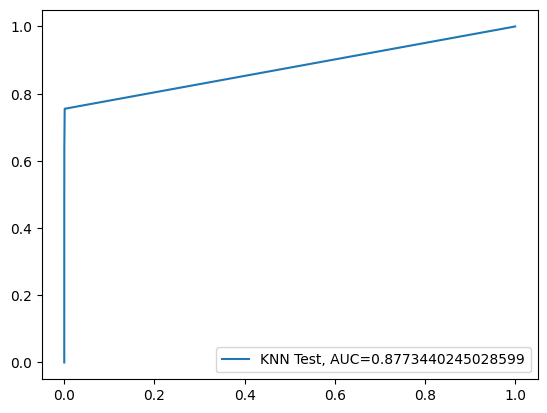

Time Taken by Model: -----176.82439494132996 second----
------------------------------------------------------------
Decision Tree Models with 'gini' & 'entropy' criteria

Decision Tree with criterion = gini
gini score: 0.9990168711925703
Confusion Matrix


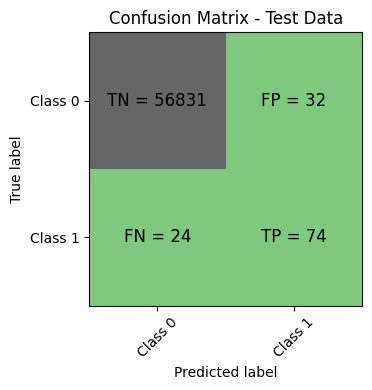

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.70      0.76      0.73        98

    accuracy                           1.00     56961
   macro avg       0.85      0.88      0.86     56961
weighted avg       1.00      1.00      1.00     56961

gini tree_roc_value: 0.8772696423591683
Tree threshold: 1.0
ROC for the test dataset: 87.7%


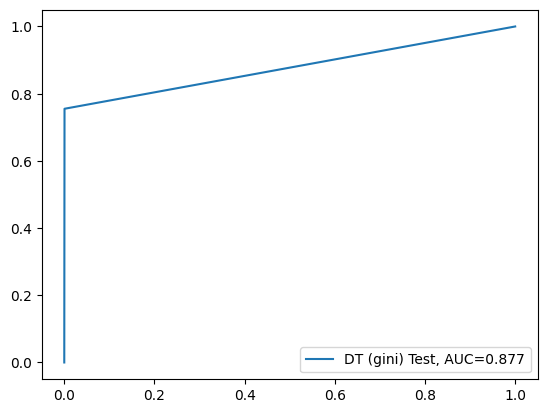


Decision Tree with criterion = entropy
entropy score: 0.9990344270641316
Confusion Matrix


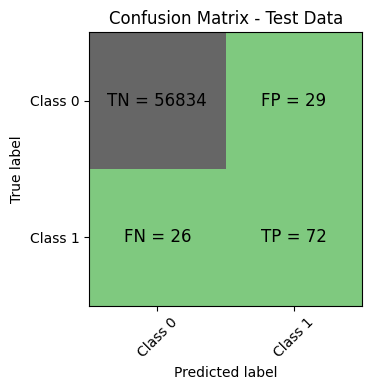

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.71      0.73      0.72        98

    accuracy                           1.00     56961
   macro avg       0.86      0.87      0.86     56961
weighted avg       1.00      1.00      1.00     56961

entropy tree_roc_value: 0.8670919399186086
Tree threshold: 1.0
ROC for the test dataset: 86.7%


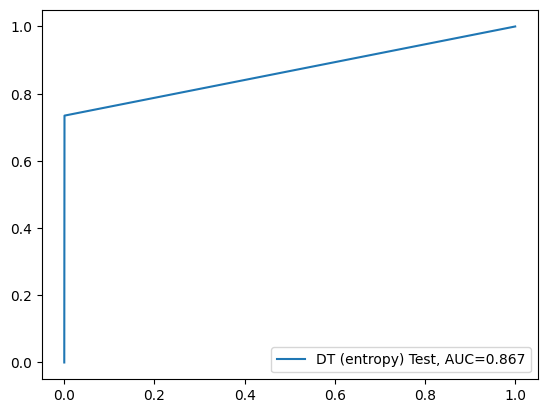

Time Taken by Model: -----43.16021108627319 second----
------------------------------------------------------------
Random Forest Model
Random Forest - Model Accuracy: 0.9995435473394076
Confusion Matrix (Random Forest)


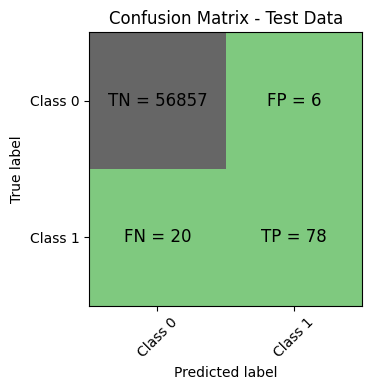

Classification Report (Random Forest)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.93      0.80      0.86        98

    accuracy                           1.00     56961
   macro avg       0.96      0.90      0.93     56961
weighted avg       1.00      1.00      1.00     56961

Random Forest roc_value: 0.9268086884086241
Random Forest threshold: 0.05
ROC for the test dataset (Random Forest): 92.7%


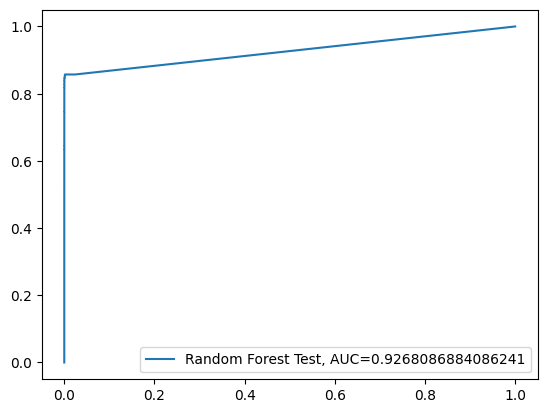

Time Taken by Model: -----212.88791346549988 second----
------------------------------------------------------------
XGBoost Model
XGBoost - Model Accuracy: 0.9994031003669177
Confusion Matrix (XGBoost)


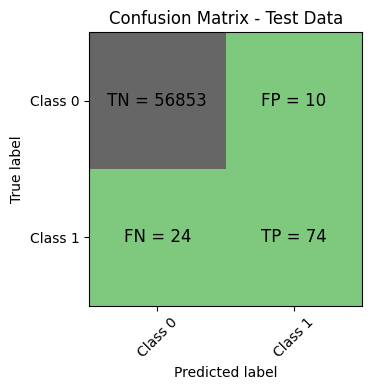

Classification Report (XGBoost)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.88      0.76      0.81        98

    accuracy                           1.00     56961
   macro avg       0.94      0.88      0.91     56961
weighted avg       1.00      1.00      1.00     56961

XGBoost roc_value: 0.9261853678389915
XGBoost threshold: 3.43664396496024e-05
ROC for the test dataset (XGBoost): 92.6%


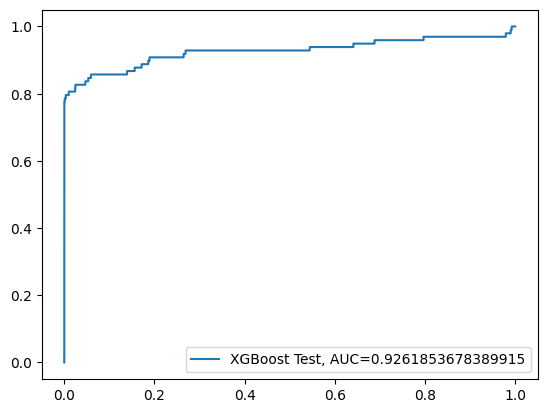

Time Taken by Model: -----6.654724836349487 second----
------------------------------------------------------------
SVM Model with sigmoid kernel
SVM accuracy_score: 0.9983497480732431
Confusion Matrix (SVM)


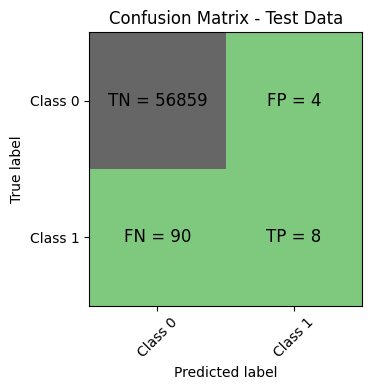

Classification Report (SVM)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.67      0.08      0.15        98

    accuracy                           1.00     56961
   macro avg       0.83      0.54      0.57     56961
weighted avg       1.00      1.00      1.00     56961

SVM roc_value: 0.48111465186464997
SVM threshold: 0.0022995563504785935
ROC for the test dataset (SVM): 48.1%


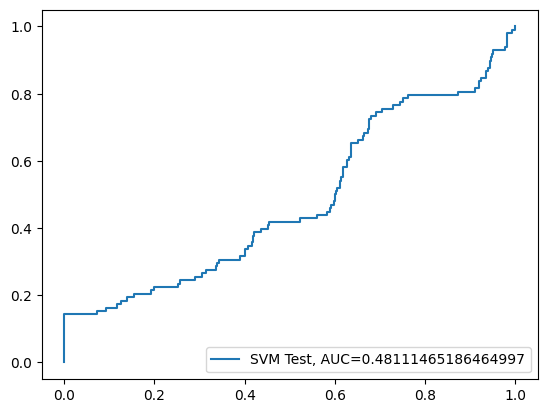

Time Taken by Model: -----407.2438769340515 second----
------------------------------------------------------------


In [ ]:
# print("Logistic Regression with L1 And L2 Regularisation")
# start_time=time.time()
# df_Results=buildAndRunLogisticModels(df_Results,"StratifiedKFold Cross Validation",X_train_SKF_cv,y_train_cv,X_test_SKF_cv,y_test_SKF_cv)
# print("Time Taken by Model: --%S seconds---"%(time.time()-start_time))
# print('-'*60)

# print("KNN Model")
# start_time=time.time()
# df_Results=buildAndRunKNNModels(df_Results,"StratifiedKFold Cross Validation",X_train_SKF_cv,y_train_cv,X_test_SKF_cv,y_test_SKF_cv)
# print("Time Taken by Model:-----%s second----"% (time.time()-start_time))
# print('-'*60)

# print("Decision Tree Models with  'gini' & 'entropy' criteria")
# start_time=time.time()
# df_Results=builtAndRunTreeModels(df_Results,"StratifiedKFold Cross Validation",X_train_SKF_cv,y_train_cv,X_test_SKF_cv,y_test_SKF_cv)
# print("Time Taken by Model:-----%s second----"% (time.time()-start_time))
# print('-'*60)

# print("Rondom Forest Model")
# start_time=time.time()
# df_Results=buildAndRunRandomForestModels(df_Results,"StratifiedKFold Cross Validation",X_train_SKF_cv,y_train_cv,X_test_SKF_cv,y_test_SKF_cv)
# print("Time Taken by Model:-----%s second----"% (time.time()-start_time))
# print('-'*60)

# print("XGBoost Model")
# start_time=time.time()
# df_Results=buildAndRunXGBoostModels(df_Results,"StratifiedKFold Cross Validation",X_train_SKF_cv,y_train_cv,X_test_SKF_cv,y_test_SKF_cv)
# print("Time Taken by Model:-----%s second----"% (time.time()-start_time))
# print('-'*60)

# print("SVM Model with sigmod kernel")
# start_time=time.time()
# df_Results=buildAndRunSVMModels(df_Results,"StratifiedKFold Cross Validation",X_train_SKF_cv,y_train_cv,X_test_SKF_cv,y_test_SKF_cv)
# print("Time Taken by Model:-----%s second----"% (time.time()-start_time))


print("Logistic Regression with L1 And L2 Regularisation")
start_time = time.time()
df_Results = buildAndRunLogisticModels(
    df_Results,
    "StratifiedKFold Cross Validation",
    X_train_SKF_cv, y_train_SKF_cv,
    X_test_SKF_cv, y_test_SKF_cv
)
print("Time Taken by Model: --%s seconds---" % (time.time() - start_time))
print('-' * 60)

print("KNN Model")
start_time = time.time()
df_Results = buildAndRunKNNModels(
    df_Results,
    "StratifiedKFold Cross Validation",
    X_train_SKF_cv, y_train_SKF_cv,
    X_test_SKF_cv, y_test_SKF_cv
)
print("Time Taken by Model: -----%s second----" % (time.time() - start_time))
print('-' * 60)

print("Decision Tree Models with 'gini' & 'entropy' criteria")
start_time = time.time()
df_Results = builtAndRunTreeModels(
    df_Results,
    "StratifiedKFold Cross Validation",
    X_train_SKF_cv, y_train_SKF_cv,
    X_test_SKF_cv, y_test_SKF_cv
)
print("Time Taken by Model: -----%s second----" % (time.time() - start_time))
print('-' * 60)

print("Random Forest Model")
start_time = time.time()
df_Results = buildAndRunRandomForestModels(
    df_Results,
    "StratifiedKFold Cross Validation",
    X_train_SKF_cv, y_train_SKF_cv,
    X_test_SKF_cv, y_test_SKF_cv
)
print("Time Taken by Model: -----%s second----" % (time.time() - start_time))
print('-' * 60)

print("XGBoost Model")
start_time = time.time()
df_Results = buildAndRunXGBoostModels(
    df_Results,
    "StratifiedKFold Cross Validation",
    X_train_SKF_cv, y_train_SKF_cv,
    X_test_SKF_cv, y_test_SKF_cv
)
print("Time Taken by Model: -----%s second----" % (time.time() - start_time))
print('-' * 60)

print("SVM Model with sigmoid kernel")
start_time = time.time()
df_Results = buildAndRunSVMModels(
    df_Results,
    "StratifiedKFold Cross Validation",
    X_train_SKF_cv, y_train_SKF_cv,
    X_test_SKF_cv, y_test_SKF_cv
)
print("Time Taken by Model: -----%s second----" % (time.time() - start_time))
print('-' * 60)



In [ ]:
df_Results

,Methodolgy,Model,Accuracy,roc_value,threshold,Methodology
0,NaN,Logistic regression with L2 Regularisation,0.998982,0.986059,0.001815,RepeatedKFold Cross validatio
1,NaN,Logistic regression with L1 Regularisation,0.999175,0.975374,0.002964,RepeatedKFold Cross validatio
2,NaN,KNN,0.999210,0.889211,0.200000,RepeatedKFold Cross Validation
3,NaN,Decision Tree (gini),0.999263,0.870060,1.000000,RepeatedKFold Cross Validation
4,NaN,Decision Tree (entropy),0.999087,0.884369,1.000000,RepeatedKFold Cross Validation
5,NaN,Random Forest,0.999491,0.935653,0.010000,RepeatedKFold Cross Validation
6,NaN,XGBoost,0.999105,0.905950,0.000006,RepeatedKFold Cross Validation
7,NaN,SVM,0.998262,0.546795,0.001797,RepeatedKFold Cross Validation
8,NaN,Logistic regression with L2 Regularisation,0.999087,0.982691,0.001846,StratifiedKFold Cross Validation
9,NaN,Logistic regression with L1 Regularisation,0.999263,0.969566,0.002157,StratifiedKFold Cross Validation


In [ ]:
# from sklearn import linear_model
# from sklearn.model_selection import KFold

# num_C=list(np.power(10.0,np.arange(-10,10)))
# cv_num=KFold(n_splits=10,shuffle=True,random_state=42)

# clf=linear_model.LogisticRegressionCV(
#     Cs=num_C,
#     penalty='l2',
#     scoring='roc_auc',
#     cv=cv_num,
#     random_state=42,
#     fit_intercept=True,
#     solver='newton-cg',
#     tol=10,
#     max_iter=10000
# )

# clf.fit(X_train_SKF_cv,y_train_SKF_cv)
# print("Max auc_roc for l2:",clf.scores_[1].mean(axis=0).max())

# print("Parameters for l2 regularistions")
# print(clf.coef_)
# print(clf.intercept_)
# print(clf.scores_)

# y_pred_l2=clf.predict(X_test)

# y_pred_probs_l2=clf.predict_proba(X_test)[:,1]

# Accuracy_l2=metrics.accuracy_score(y_pred=y_pred_l2,y_true=y_test)

# print("Accuary of Logistic model with l2 regularistion: {0}".format(Accuracy_l2))

# from sklearn.metrics import roc_auc_score
# l2_roc_value=roc_auc_score(y_test,y_pred_probs_l2)
# print("l2 roc_value :{0}".format(l2_roc_value))
# fpr,tpr,thresholds=metrics.roc_curve(y_test,y_pred_probs_l2)
# threshold=thresholds[np.argmax(tpr-fpr)]
# print("l2 threshold: {0}".format(threshold))


from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, accuracy_score
from sklearn import metrics

# 1. Define range of C values
Cs = list(np.power(10.0, np.arange(-10, 10)))

# 2. Use StratifiedKFold for classification
cv_num = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# 3. Logistic Regression with L2 + CV
clf = LogisticRegressionCV(
    Cs=Cs,
    penalty='l2',
    scoring='roc_auc',
    cv=cv_num,
    random_state=42,
    fit_intercept=True,
    solver='lbfgs',      # good with L2
    tol=1e-4,
    max_iter=10000,
    n_jobs=-1
)

# 4. Fit on training fold
clf.fit(X_train_SKF_cv, y_train_SKF_cv)

# 5. Max ROC-AUC across C values (class label 1)
print("Max auc_roc for L2:",
      clf.scores_[1].mean(axis=0).max())

print("\nParameters for L2 regularisation:")
print("Coefficients:\n", clf.coef_)
print("Intercept:\n", clf.intercept_)

# 6. Predict on test fold
y_pred_l2 = clf.predict(X_test_SKF_cv)
y_pred_probs_l2 = clf.predict_proba(X_test_SKF_cv)[:, 1]

# 7. Accuracy
Accuracy_l2 = accuracy_score(y_test_SKF_cv, y_pred_l2)
print("\nAccuracy of Logistic model with L2 regularisation:",
      Accuracy_l2)

# 8. ROC-AUC
l2_roc_value = roc_auc_score(y_test_SKF_cv, y_pred_probs_l2)
print("L2 ROC value:", l2_roc_value)

# 9. Best threshold using Youden's J (tpr - fpr)
fpr, tpr, thresholds = metrics.roc_curve(y_test_SKF_cv, y_pred_probs_l2)
best_threshold = thresholds[np.argmax(tpr - fpr)]
print("L2 best threshold:", best_threshold)



Max auc_roc for L2: 0.9836374613677237

Parameters for L2 regularisation:
Coefficients:
 [[ 9.33189940e-03  4.22410405e-02 -8.25283197e-02  2.36467932e-01
   9.02832751e-02 -4.66361004e-02 -3.51310615e-02 -1.12437940e-01
  -8.44228618e-02 -1.77486637e-01  1.35724305e-01 -1.99119610e-01
  -3.89134848e-02 -3.81401903e-01 -1.35561403e-02 -1.05501851e-01
  -8.95481720e-02 -5.35261673e-03  1.50889630e-02 -1.80568262e-02
   4.34902256e-02  2.61869065e-02 -1.33638620e-02 -1.61976316e-02
  -7.33660119e-03  6.94642345e-03 -3.68028211e-03  1.01903264e-03
   3.29180256e-04  1.86581332e-02]]
Intercept:
 [-7.68969321]

Accuracy of Logistic model with L2 regularisation: 0.9990870946788153
L2 ROC value: 0.9826805350633299
L2 best threshold: 0.001878951852333572


In [ ]:
clf.coef_


array([[ 9.33189940e-03,  4.22410405e-02, -8.25283197e-02,
         2.36467932e-01,  9.02832751e-02, -4.66361004e-02,
        -3.51310615e-02, -1.12437940e-01, -8.44228618e-02,
        -1.77486637e-01,  1.35724305e-01, -1.99119610e-01,
        -3.89134848e-02, -3.81401903e-01, -1.35561403e-02,
        -1.05501851e-01, -8.95481720e-02, -5.35261673e-03,
         1.50889630e-02, -1.80568262e-02,  4.34902256e-02,
         2.61869065e-02, -1.33638620e-02, -1.61976316e-02,
        -7.33660119e-03,  6.94642345e-03, -3.68028211e-03,
         1.01903264e-03,  3.29180256e-04,  1.86581332e-02]])

In [ ]:
coefficients=pd.concat([pd.DataFrame(X.columns),pd.DataFrame(np.transpose(clf.coef_))],axis=1)
coefficients.columns=['Feature','Importance Coefficient']

In [ ]:
coefficients

,Feature,Importance Coefficient
0,V1,0.009332
1,V2,0.042241
2,V3,-0.082528
3,V4,0.236468
4,V5,0.090283
5,V6,-0.046636
6,V7,-0.035131
7,V8,-0.112438
8,V9,-0.084423
9,V10,-0.177487


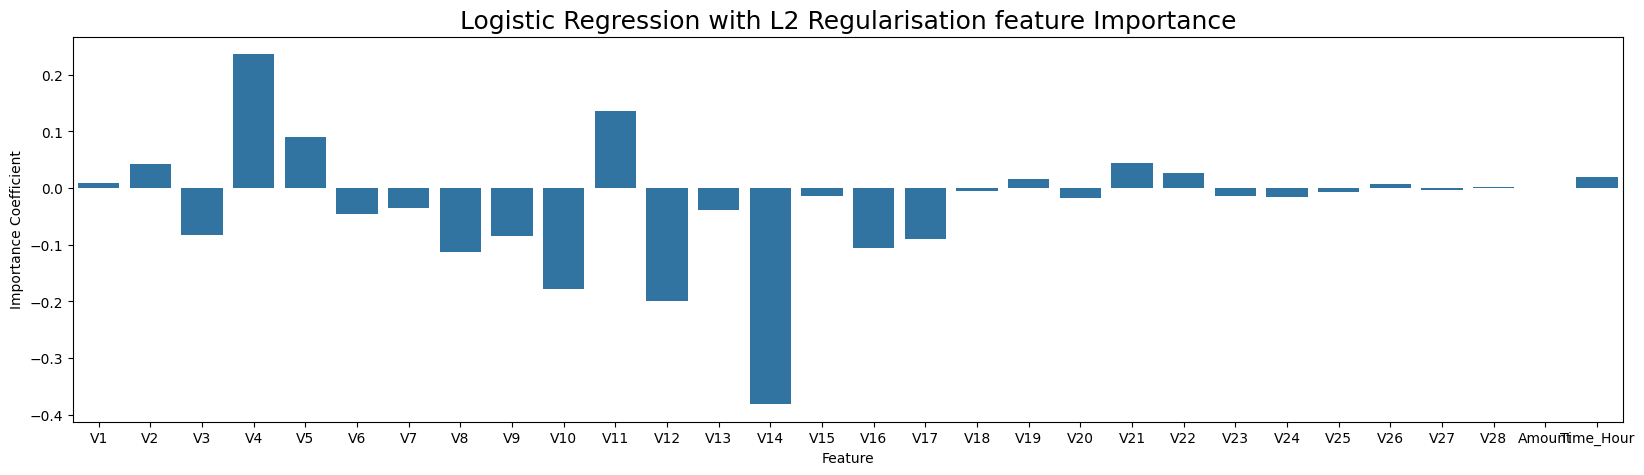

In [ ]:
plt.figure(figsize=(20,5))
sns.barplot(x='Feature',y='Importance Coefficient',data=coefficients)
plt.title("Logistic Regression with L2 Regularisation feature Importance",fontsize=18)
plt.show()

In [ ]:
from sklearn.model_selection import StratifiedKFold
from imblearn.over_sampling import RandomOverSampler
skf=StratifiedKFold(n_splits=5,random_state=None)
for  fold, (train_index,test_index) in enumerate(skf.split(X,y),1):
  X_train=X.loc[train_index]
  y_train=y.loc[train_index]
  X_test=X.loc[test_index]
  y_test=y.loc[test_index]
  ROS=RandomOverSampler(sampling_strategy=0.5)
  X_over,y_over=ROS.fit_resample(X_train,y_train)

X_over=pd.DataFrame(data=X_over,columns=cols)

Logistic Regression with l1 And l2 Regularistion

Accuracy of logistic model with L2 regularisation: 0.9860430821088113
Confusion Matrix (L2)


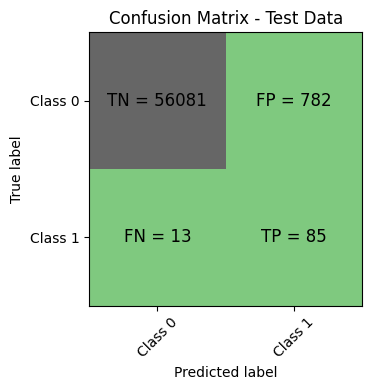

Classification Report (L2)
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     56863
           1       0.10      0.87      0.18        98

    accuracy                           0.99     56961
   macro avg       0.55      0.93      0.58     56961
weighted avg       1.00      0.99      0.99     56961

L2 roc_value: 0.980667102850496
L2 threshold: 0.3254296577019465
ROC (AUC) for the test dataset (L2): 98.1%


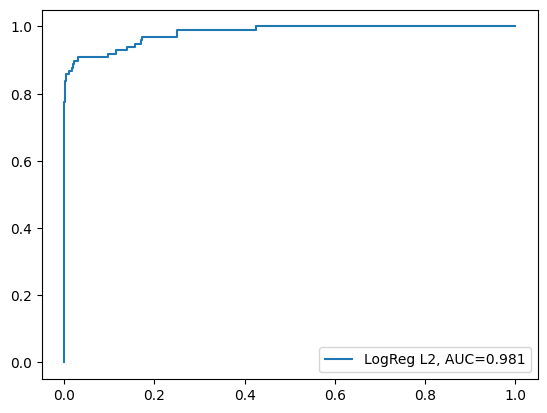


Accuracy of logistic model with L1 regularisation: 0.9859728586225663
Confusion Matrix (L1)


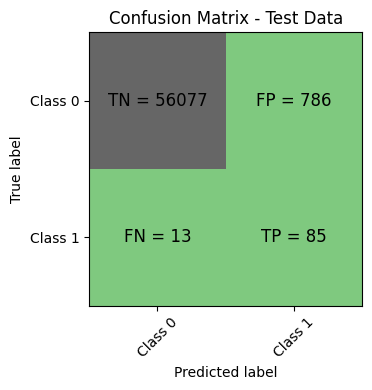

Classification Report (L1)
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     56863
           1       0.10      0.87      0.18        98

    accuracy                           0.99     56961
   macro avg       0.55      0.93      0.58     56961
weighted avg       1.00      0.99      0.99     56961

L1 roc_value: 0.9806448510149888
L1 threshold: 0.3263461297060462
ROC (AUC) for the test dataset (L1): 98.1%


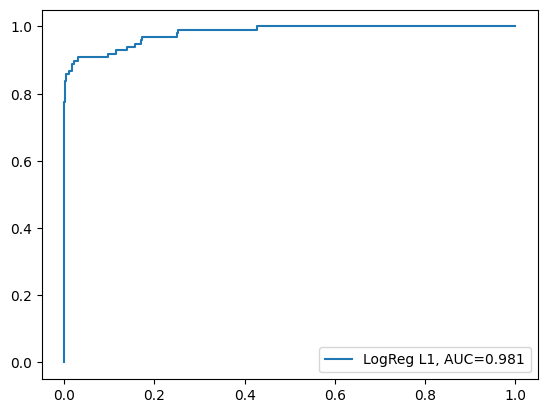

Time Taken by Model:-----1481.9549660682678 second----
------------------------------------------------------------
KNN Model
KNN model score (test accuracy): 0.9980688541282632
Confusion matrix (KNN)


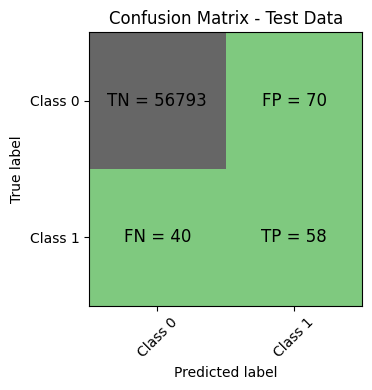

Classification Report (KNN)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.45      0.59      0.51        98

    accuracy                           1.00     56961
   macro avg       0.73      0.80      0.76     56961
weighted avg       1.00      1.00      1.00     56961

KNN roc_value: 0.805604465728046
KNN threshold: 0.2
ROC for the test dataset (KNN): 80.6%


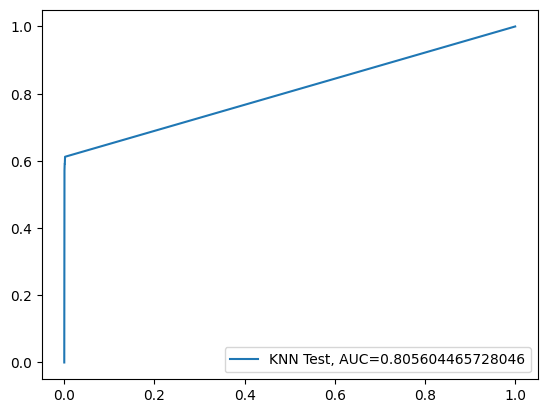

Time Taken by Model:----1742.948893547058 seconds----
------------------------------------------------------------
Decision Tree Models with  'gini' & 'entropy' criteria

Decision Tree with criterion = gini
gini score: 0.9990168711925703
Confusion Matrix


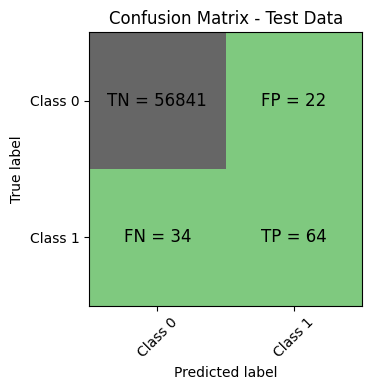

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.74      0.65      0.70        98

    accuracy                           1.00     56961
   macro avg       0.87      0.83      0.85     56961
weighted avg       1.00      1.00      1.00     56961

gini tree_roc_value: 0.8263371648362139
Tree threshold: 1.0
ROC for the test dataset: 82.6%


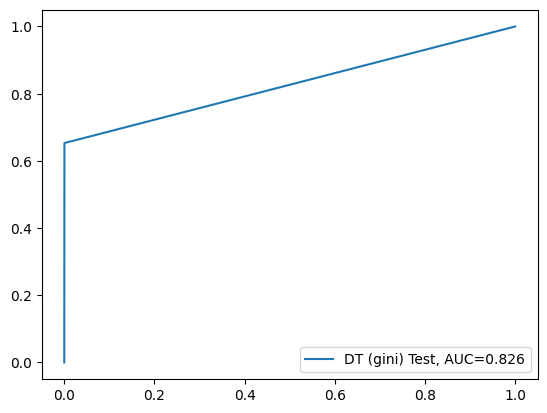


Decision Tree with criterion = entropy
entropy score: 0.9991748740366215
Confusion Matrix


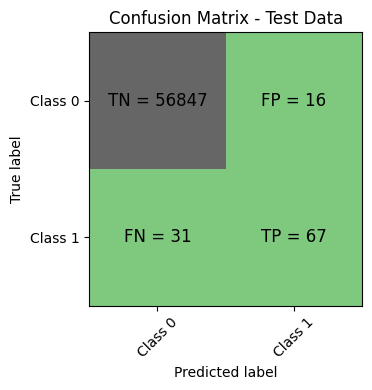

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.81      0.68      0.74        98

    accuracy                           1.00     56961
   macro avg       0.90      0.84      0.87     56961
weighted avg       1.00      1.00      1.00     56961

entropy tree_roc_value: 0.84169604566938
Tree threshold: 1.0
ROC for the test dataset: 84.2%


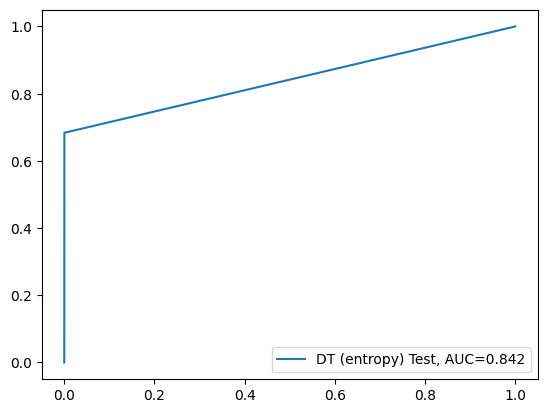

Time Taken by Model:-----30.42470073699951 second----
------------------------------------------------------------
Random Forest Model
Random Forest - Model Accuracy: 0.999490879724724
Confusion Matrix (Random Forest)


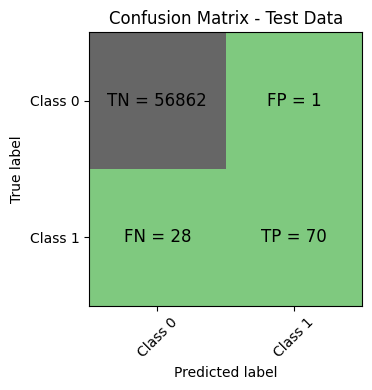

Classification Report (Random Forest)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.99      0.71      0.83        98

    accuracy                           1.00     56961
   macro avg       0.99      0.86      0.91     56961
weighted avg       1.00      1.00      1.00     56961

Random Forest roc_value: 0.9409316053945628
Random Forest threshold: 0.01
ROC for the test dataset (Random Forest): 94.1%


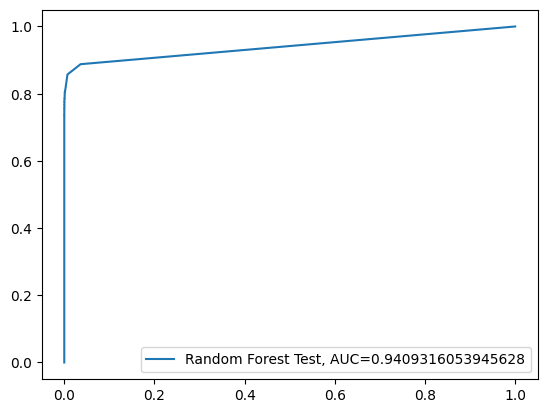

Time Taken by Model:----180.3489100933075 seconds----
------------------------------------------------------------
XGBoost Model
XGBoost - Model Accuracy: 0.9994733238531627
Confusion Matrix (XGBoost)


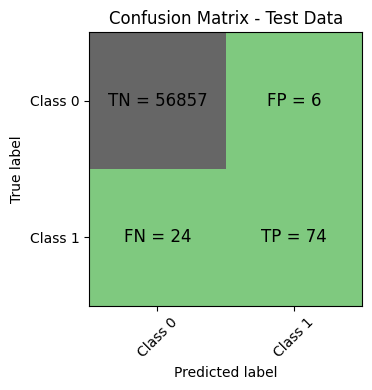

Classification Report (XGBoost)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.93      0.76      0.83        98

    accuracy                           1.00     56961
   macro avg       0.96      0.88      0.92     56961
weighted avg       1.00      1.00      1.00     56961

XGBoost roc_value: 0.9752746217457139
XGBoost threshold: 3.9116624975577e-05
ROC for the test dataset (XGBoost): 97.5%


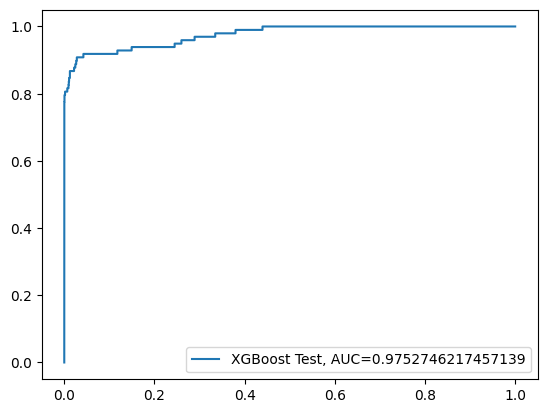

Time Taken by Model:-----7.526116371154785 second----
------------------------------------------------------------


In [ ]:
Data_Imbalance_Handiling="Random Oversampling with StratifiedKFold CV"

print("Logistic Regression with l1 And l2 Regularistion")
start_time=time.time()
df_Results=buildAndRunLogisticModels(df_Results,Data_Imbalance_Handiling,X_over,y_over,X_test,y_test)
print("Time Taken by Model:-----%s second----"% (time.time()-start_time))
print('-'*60)

print("KNN Model")
df_Results=buildAndRunKNNModels(df_Results,Data_Imbalance_Handiling,X_over,y_over,X_test,y_test)
print("Time Taken by Model:----%s seconds----"%(time.time()-start_time))
print('-'*60)

print("Decision Tree Models with  'gini' & 'entropy' criteria")
start_time=time.time()
df_Results=builtAndRunTreeModels(df_Results,Data_Imbalance_Handiling,X_over,y_over,X_test,y_test)
print("Time Taken by Model:-----%s second----"% (time.time()-start_time))
print('-'*60)

print("Random Forest Model")
df_Results=buildAndRunRandomForestModels(df_Results,Data_Imbalance_Handiling,X_over,y_over,X_test,y_test)
print("Time Taken by Model:----%s seconds----"%(time.time()-start_time))
print('-'*60)

print("XGBoost Model")
start_time=time.time()
df_Results=buildAndRunXGBoostModels(df_Results,Data_Imbalance_Handiling,X_over,y_over,X_test,y_test)
print("Time Taken by Model:-----%s second----"% (time.time()-start_time))
print('-'*60)

# print("SVM model")
# df_Results=buildAndRunSVMModels(df_Results,Data_Imbalance_Handiling,X_over,y_over,X_test,y_test)
# print("Time Taken by Model:----%s seconds----"%(time.time()-start_time))


In [ ]:
df_Results

,Methodolgy,Model,Accuracy,roc_value,threshold,Methodology
0,NaN,Logistic regression with L2 Regularisation,0.998982,0.986059,0.001815,RepeatedKFold Cross validatio
1,NaN,Logistic regression with L1 Regularisation,0.999175,0.975374,0.002964,RepeatedKFold Cross validatio
2,NaN,KNN,0.999210,0.889211,0.200000,RepeatedKFold Cross Validation
3,NaN,Decision Tree (gini),0.999263,0.870060,1.000000,RepeatedKFold Cross Validation
4,NaN,Decision Tree (entropy),0.999087,0.884369,1.000000,RepeatedKFold Cross Validation
5,NaN,Random Forest,0.999491,0.935653,0.010000,RepeatedKFold Cross Validation
6,NaN,XGBoost,0.999105,0.905950,0.000006,RepeatedKFold Cross Validation
7,NaN,SVM,0.998262,0.546795,0.001797,RepeatedKFold Cross Validation
8,NaN,Logistic regression with L2 Regularisation,0.999087,0.982691,0.001846,StratifiedKFold Cross Validation
9,NaN,Logistic regression with L1 Regularisation,0.999263,0.969566,0.002157,StratifiedKFold Cross Validation


In [ ]:
from sklearn.model_selection import StratifiedKFold
from imblearn import over_sampling

skf=StratifiedKFold(n_splits=5,random_state=None)
for fold, (train_index,test_index) in enumerate(skf.split(X,y),1):
  X_train=X.loc[train_index]
  y_train=y.loc[train_index]
  X_test=X.loc[test_index]
  y_test=y.loc[test_index]
  SMOTE=over_sampling.SMOTE(sampling_strategy=0.5)
  X_train_Smote,y_train_Smote=SMOTE.fit_resample(X_train,y_train)

X_train_Smote=pd.DataFrame(data=X_train_Smote,columns=cols)


Logistic Regression with l1 And l2 Regularistion

Accuracy of logistic model with L2 regularisation: 0.9921349695405628
Confusion Matrix (L2)


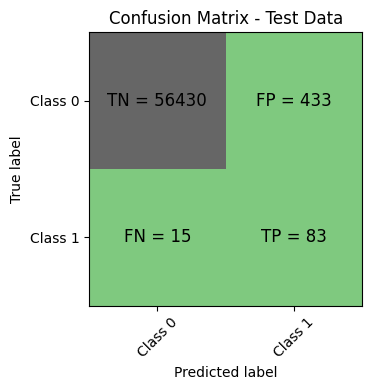

Classification Report (L2)
              precision    recall  f1-score   support

           0       1.00      0.99      1.00     56863
           1       0.16      0.85      0.27        98

    accuracy                           0.99     56961
   macro avg       0.58      0.92      0.63     56961
weighted avg       1.00      0.99      0.99     56961

L2 roc_value: 0.9749837328315425
L2 threshold: 0.22293961133461065
ROC (AUC) for the test dataset (L2): 97.5%


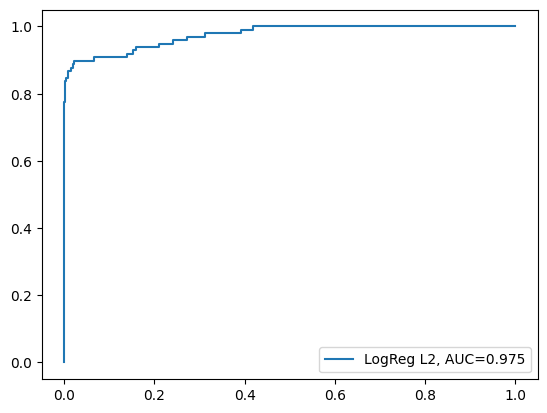


Accuracy of logistic model with L1 regularisation: 0.9921174136690016
Confusion Matrix (L1)


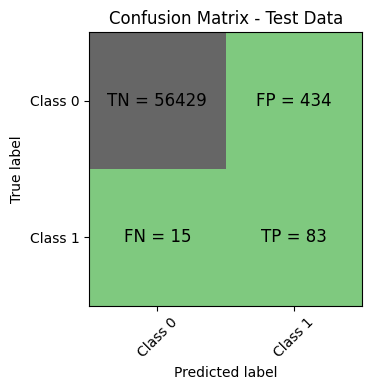

Classification Report (L1)
              precision    recall  f1-score   support

           0       1.00      0.99      1.00     56863
           1       0.16      0.85      0.27        98

    accuracy                           0.99     56961
   macro avg       0.58      0.92      0.63     56961
weighted avg       1.00      0.99      0.99     56961

L1 roc_value: 0.9749246936873337
L1 threshold: 0.22154915504725745
ROC (AUC) for the test dataset (L1): 97.5%


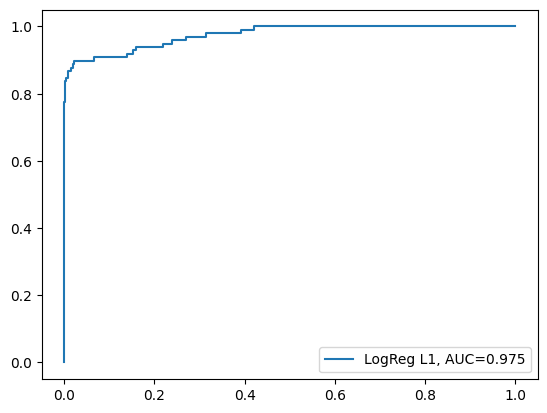

Time Taken by Model: ------1488.8023920059204 second-----
--------------------------------------------------------------------------------
KNN Model
KNN model score (test accuracy): 0.9948912413756781
Confusion matrix (KNN)


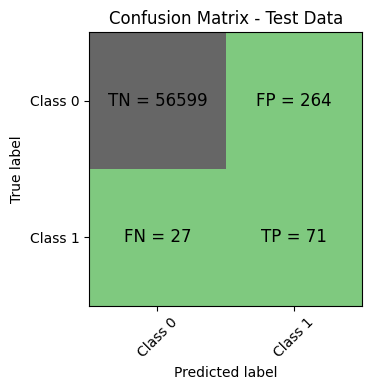

Classification Report (KNN)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.21      0.72      0.33        98

    accuracy                           0.99     56961
   macro avg       0.61      0.86      0.66     56961
weighted avg       1.00      0.99      1.00     56961

KNN roc_value: 0.8603563631456487
KNN threshold: 0.6
ROC for the test dataset (KNN): 86.0%


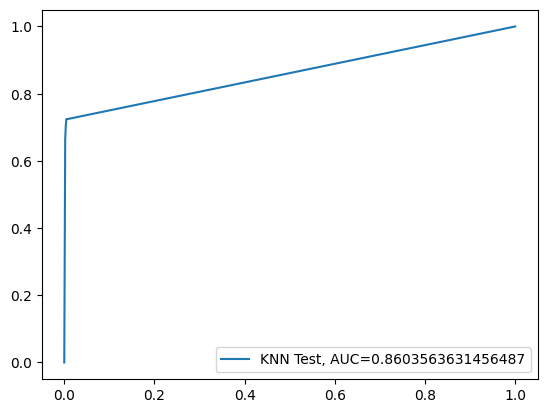

Time Taken by Model: ------260.67799854278564 second-----
--------------------------------------------------------------------------------
Decision Tree Models with 'gini' & 'entropy' criteria

Decision Tree with criterion = gini
gini score: 0.9977879601832833
Confusion Matrix


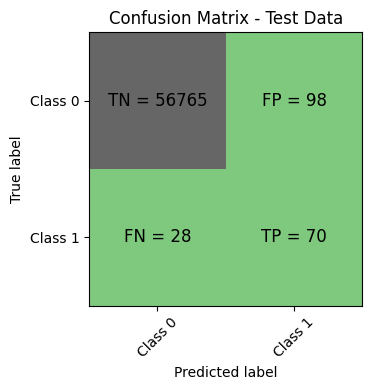

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.42      0.71      0.53        98

    accuracy                           1.00     56961
   macro avg       0.71      0.86      0.76     56961
weighted avg       1.00      1.00      1.00     56961

gini tree_roc_value: 0.8562811368678102
Tree threshold: 1.0
ROC for the test dataset: 85.6%


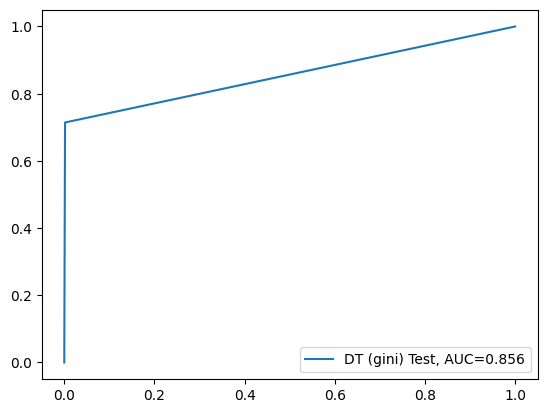


Decision Tree with criterion = entropy
entropy score: 0.9968223872474149
Confusion Matrix


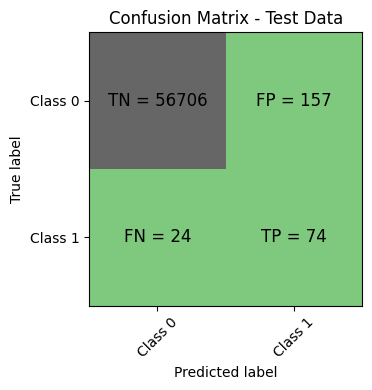

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.32      0.76      0.45        98

    accuracy                           1.00     56961
   macro avg       0.66      0.88      0.72     56961
weighted avg       1.00      1.00      1.00     56961

entropy tree_roc_value: 0.8761705093552817
Tree threshold: 1.0
ROC for the test dataset: 87.6%


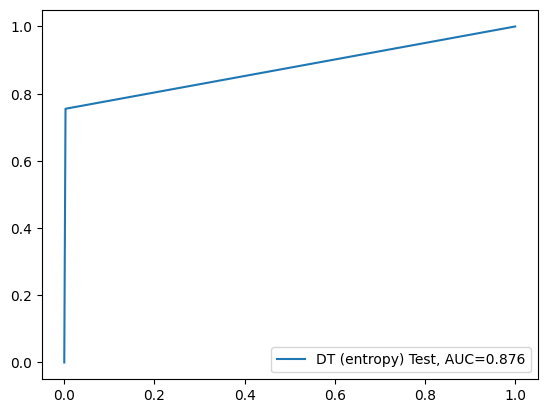

Time Taken by Model: ------54.666149854660034 second-----
--------------------------------------------------------------------------------
Random Forest Model
Random Forest - Model Accuracy: 0.9995084355962852
Confusion Matrix (Random Forest)


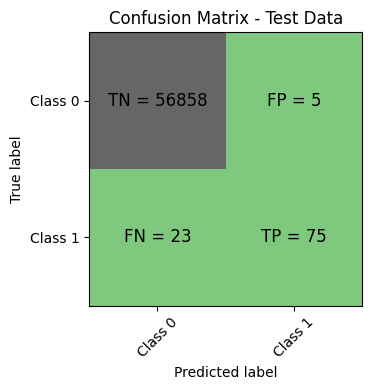

Classification Report (Random Forest)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.94      0.77      0.84        98

    accuracy                           1.00     56961
   macro avg       0.97      0.88      0.92     56961
weighted avg       1.00      1.00      1.00     56961

Random Forest roc_value: 0.9582782570496149
Random Forest threshold: 0.06
ROC for the test dataset (Random Forest): 95.8%


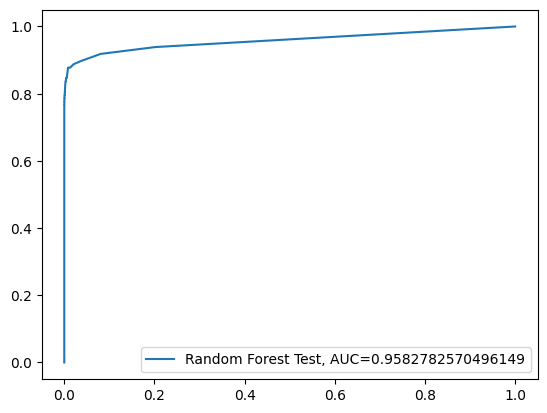

Time Taken by Model: ------236.85086178779602 second-----
--------------------------------------------------------------------------------
XGBoost Model
XGBoost - Model Accuracy: 0.9994382121100402
Confusion Matrix (XGBoost)


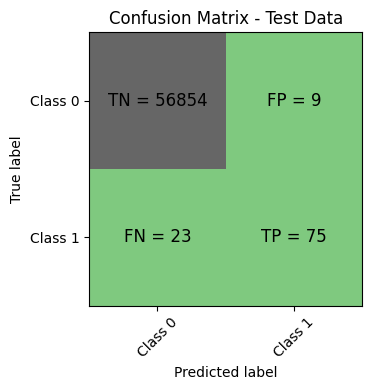

Classification Report (XGBoost)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.89      0.77      0.82        98

    accuracy                           1.00     56961
   macro avg       0.95      0.88      0.91     56961
weighted avg       1.00      1.00      1.00     56961

XGBoost roc_value: 0.9736579541159974
XGBoost threshold: 1.577890543558169e-05
ROC for the test dataset (XGBoost): 97.4%


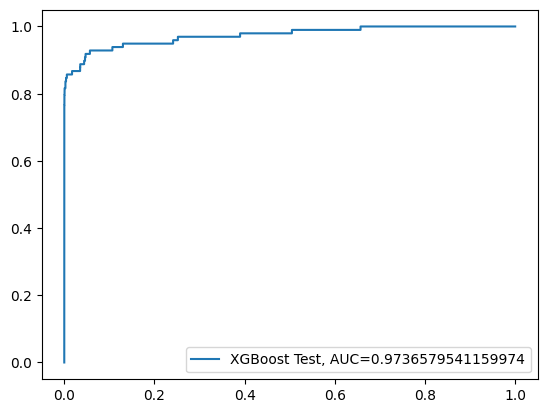

Time Taken by Model: ------9.782057762145996 second-----
--------------------------------------------------------------------------------


In [ ]:
Data_Imbalance_Handiling="SMOTE Oversampling  with StratifiedKFold CV"

print("Logistic Regression with l1 And l2 Regularistion")
start_time=time.time()
df_Results=buildAndRunLogisticModels(df_Results,Data_Imbalance_Handiling,X_train_Smote,y_train_Smote,X_test,y_test)
print("Time Taken by Model: ------%s second-----"%(time.time()-start_time))
print('-'*80)

print("KNN Model")
start_time=time.time()
df_Results=buildAndRunKNNModels(df_Results,Data_Imbalance_Handiling,X_train_Smote,y_train_Smote,X_test,y_test)
print("Time Taken by Model: ------%s second-----"%(time.time()-start_time))
print('-'*80)

print("Decision Tree Models with 'gini' & 'entropy' criteria")
start_time=time.time()
df_Results=builtAndRunTreeModels(df_Results,Data_Imbalance_Handiling,X_train_Smote,y_train_Smote,X_test,y_test)
print("Time Taken by Model: ------%s second-----"%(time.time()-start_time))
print('-'*80)

print("Random Forest Model")
start_time=time.time()
df_Results=buildAndRunRandomForestModels(df_Results,Data_Imbalance_Handiling,X_train_Smote,y_train_Smote,X_test,y_test)
print("Time Taken by Model: ------%s second-----"%(time.time()-start_time))
print('-'*80)

print("XGBoost Model")
start_time=time.time()
df_Results=buildAndRunXGBoostModels(df_Results,Data_Imbalance_Handiling,X_train_Smote,y_train_Smote,X_test,y_test)
print("Time Taken by Model: ------%s second-----"%(time.time()-start_time))
print('-'*80)

In [ ]:

df_Results

,Methodolgy,Model,Accuracy,roc_value,threshold,Methodology
0,NaN,Logistic regression with L2 Regularisation,0.998982,0.986059,0.001815,RepeatedKFold Cross validatio
1,NaN,Logistic regression with L1 Regularisation,0.999175,0.975374,0.002964,RepeatedKFold Cross validatio
2,NaN,KNN,0.999210,0.889211,0.200000,RepeatedKFold Cross Validation
3,NaN,Decision Tree (gini),0.999263,0.870060,1.000000,RepeatedKFold Cross Validation
4,NaN,Decision Tree (entropy),0.999087,0.884369,1.000000,RepeatedKFold Cross Validation
5,NaN,Random Forest,0.999491,0.935653,0.010000,RepeatedKFold Cross Validation
6,NaN,XGBoost,0.999105,0.905950,0.000006,RepeatedKFold Cross Validation
7,NaN,SVM,0.998262,0.546795,0.001797,RepeatedKFold Cross Validation
8,NaN,Logistic regression with L2 Regularisation,0.999087,0.982691,0.001846,StratifiedKFold Cross Validation
9,NaN,Logistic regression with L1 Regularisation,0.999263,0.969566,0.002157,StratifiedKFold Cross Validation


oversampling with ADASYN Oversampling

In [ ]:
from sklearn.model_selection import StratifiedKFold
from imblearn import over_sampling

skf=StratifiedKFold(n_splits=5,random_state=None)
for fold, (train_index,test_index) in enumerate(skf.split(X,y),1):
  X_train=X.loc[train_index]
  y_train=y.loc[train_index]
  X_test=X.loc[test_index]
  y_test=y.loc[test_index]
  ADASYN=over_sampling.ADASYN(random_state=0)
  X_train_ADASYN,y_train_ADASYN=ADASYN.fit_resample(X_train,y_train)

X_train_ADASYN=pd.DataFrame(data=X_train_ADASYN,columns=cols)

Logistic Regression with l1 And l2 Regularistion

Accuracy of logistic model with L2 regularisation: 0.9579010199961377
Confusion Matrix (L2)


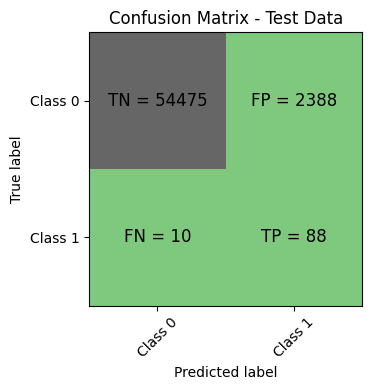

Classification Report (L2)
              precision    recall  f1-score   support

           0       1.00      0.96      0.98     56863
           1       0.04      0.90      0.07        98

    accuracy                           0.96     56961
   macro avg       0.52      0.93      0.52     56961
weighted avg       1.00      0.96      0.98     56961

L2 roc_value: 0.9741445335674321
L2 threshold: 0.612305606941323
ROC (AUC) for the test dataset (L2): 97.4%


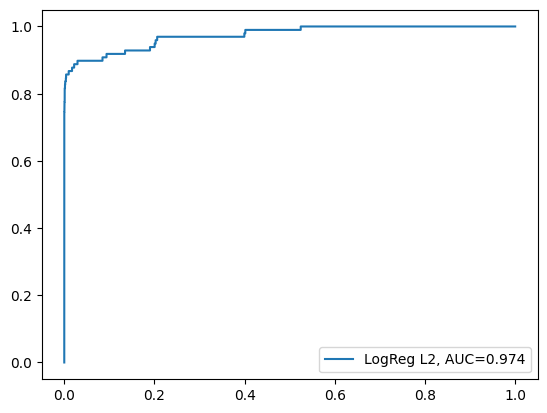


Accuracy of logistic model with L1 regularisation: 0.9580239110970664
Confusion Matrix (L1)


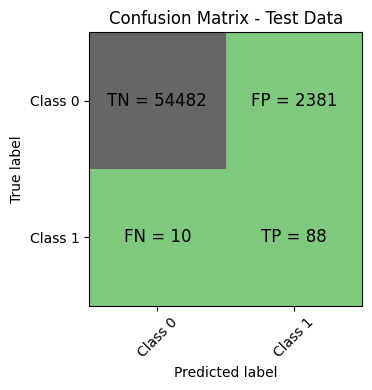

Classification Report (L1)
              precision    recall  f1-score   support

           0       1.00      0.96      0.98     56863
           1       0.04      0.90      0.07        98

    accuracy                           0.96     56961
   macro avg       0.52      0.93      0.52     56961
weighted avg       1.00      0.96      0.98     56961

L1 roc_value: 0.974013175957825
L1 threshold: 0.6116988223116637
ROC (AUC) for the test dataset (L1): 97.4%


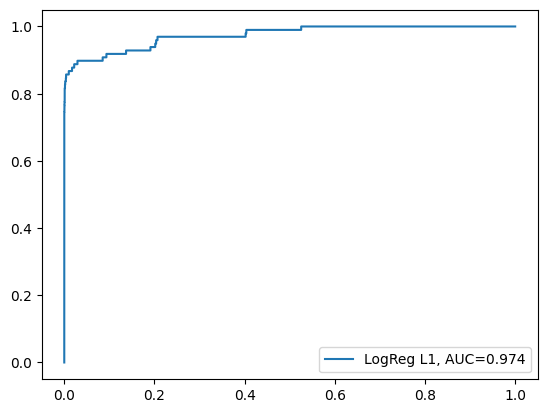

Time Taken by Model: ------3030.3641831874847 second-----
--------------------------------------------------------------------------------
KNN Model
KNN model score (test accuracy): 0.9945050122013307
Confusion matrix (KNN)


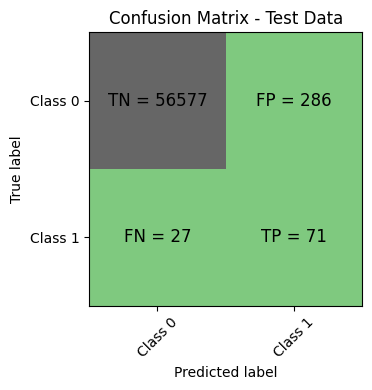

Classification Report (KNN)
              precision    recall  f1-score   support

           0       1.00      0.99      1.00     56863
           1       0.20      0.72      0.31        98

    accuracy                           0.99     56961
   macro avg       0.60      0.86      0.65     56961
weighted avg       1.00      0.99      1.00     56961

KNN roc_value: 0.8601937811862167
KNN threshold: 0.6
ROC for the test dataset (KNN): 86.0%


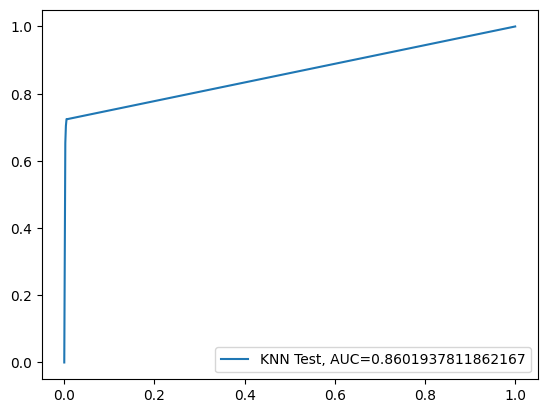

Time Taken by Model: ------354.8646659851074 second-----
--------------------------------------------------------------------------------
Decision Tree Models with 'gini' & 'entropy' criteria

Decision Tree with criterion = gini
gini score: 0.9979459630273345
Confusion Matrix


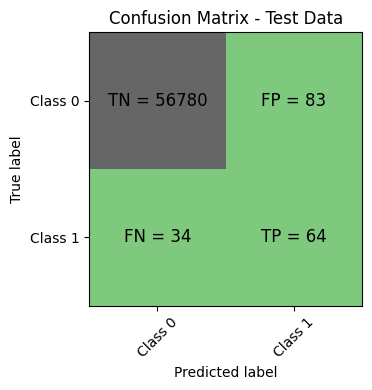

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.44      0.65      0.52        98

    accuracy                           1.00     56961
   macro avg       0.72      0.83      0.76     56961
weighted avg       1.00      1.00      1.00     56961

gini tree_roc_value: 0.8258007879303172
Tree threshold: 1.0
ROC for the test dataset: 82.6%


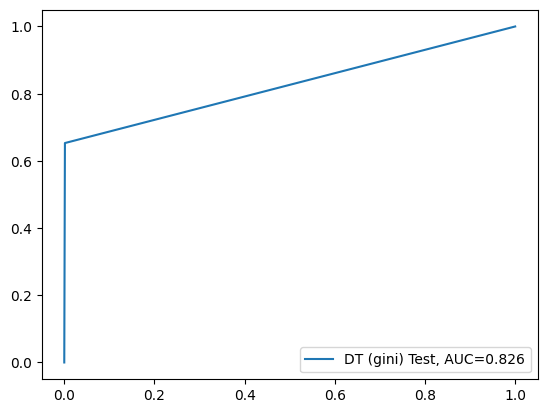


Decision Tree with criterion = entropy
entropy score: 0.9954179175225154
Confusion Matrix


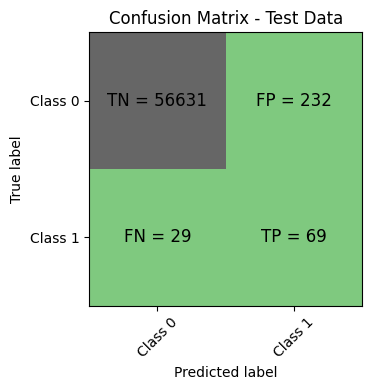

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.23      0.70      0.35        98

    accuracy                           1.00     56961
   macro avg       0.61      0.85      0.67     56961
weighted avg       1.00      1.00      1.00     56961

entropy tree_roc_value: 0.8500008254713172
Tree threshold: 1.0
ROC for the test dataset: 85.0%


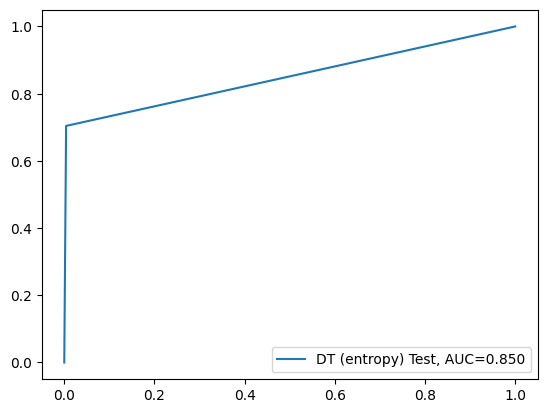

Time Taken by Model: ------96.05450463294983 second-----
--------------------------------------------------------------------------------
Random Forest Model
Random Forest - Model Accuracy: 0.9995259914678464
Confusion Matrix (Random Forest)


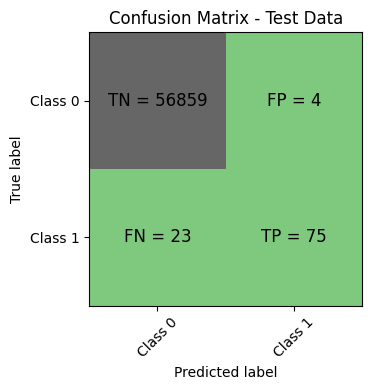

Classification Report (Random Forest)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.95      0.77      0.85        98

    accuracy                           1.00     56961
   macro avg       0.97      0.88      0.92     56961
weighted avg       1.00      1.00      1.00     56961

Random Forest roc_value: 0.9632721790684162
Random Forest threshold: 0.03
ROC for the test dataset (Random Forest): 96.3%


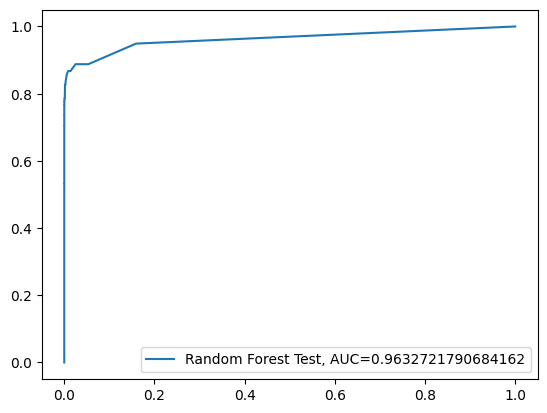

Time Taken by Model: ------359.21102690696716 second-----
--------------------------------------------------------------------------------
XGBoost Model
XGBoost - Model Accuracy: 0.9994031003669177
Confusion Matrix (XGBoost)


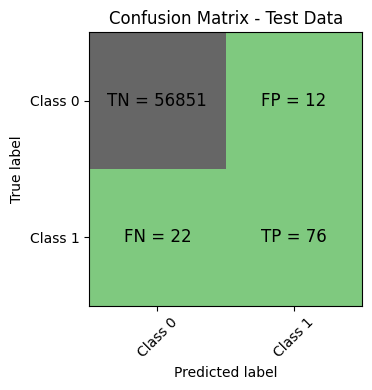

Classification Report (XGBoost)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.86      0.78      0.82        98

    accuracy                           1.00     56961
   macro avg       0.93      0.89      0.91     56961
weighted avg       1.00      1.00      1.00     56961

XGBoost roc_value: 0.9721593647746984
XGBoost threshold: 0.006340480409562588
ROC for the test dataset (XGBoost): 97.2%


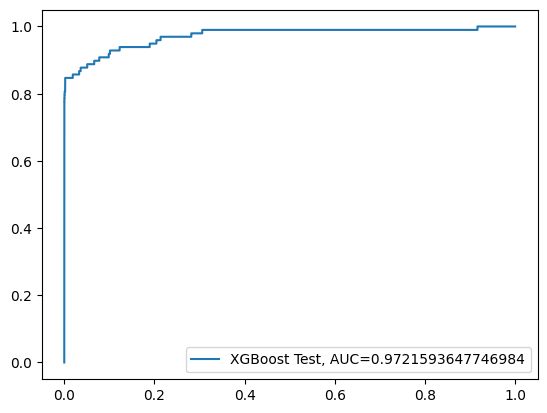

Time Taken by Model: ------12.172462701797485 second-----
--------------------------------------------------------------------------------


In [ ]:
Data_Imbalance_Handiling="ADASYN Oversampling  with StratifiedKFold CV"

print("Logistic Regression with l1 And l2 Regularistion")
start_time=time.time()
df_Results=buildAndRunLogisticModels(df_Results,Data_Imbalance_Handiling,X_train_ADASYN,y_train_ADASYN,X_test,y_test)
print("Time Taken by Model: ------%s second-----"%(time.time()-start_time))
print('-'*80)

print("KNN Model")
start_time=time.time()
df_Results=buildAndRunKNNModels(df_Results,Data_Imbalance_Handiling,X_train_ADASYN,y_train_ADASYN,X_test,y_test)
print("Time Taken by Model: ------%s second-----"%(time.time()-start_time))
print('-'*80)

print("Decision Tree Models with 'gini' & 'entropy' criteria")
start_time=time.time()
df_Results=builtAndRunTreeModels(df_Results,Data_Imbalance_Handiling,X_train_ADASYN,y_train_ADASYN,X_test,y_test)
print("Time Taken by Model: ------%s second-----"%(time.time()-start_time))
print('-'*80)

print("Random Forest Model")
start_time=time.time()
df_Results=buildAndRunRandomForestModels(df_Results,Data_Imbalance_Handiling,X_train_ADASYN,y_train_ADASYN,X_test,y_test)
print("Time Taken by Model: ------%s second-----"%(time.time()-start_time))
print('-'*80)

print("XGBoost Model")
start_time=time.time()
df_Results=buildAndRunXGBoostModels(df_Results,Data_Imbalance_Handiling,X_train_ADASYN,y_train_ADASYN,X_test,y_test)
print("Time Taken by Model: ------%s second-----"%(time.time()-start_time))
print('-'*80)

In [ ]:
df_Results

,Methodolgy,Model,Accuracy,roc_value,threshold,Methodology
0,NaN,Logistic regression with L2 Regularisation,0.998982,0.986059,0.001815,RepeatedKFold Cross validatio
1,NaN,Logistic regression with L1 Regularisation,0.999175,0.975374,0.002964,RepeatedKFold Cross validatio
2,NaN,KNN,0.999210,0.889211,0.200000,RepeatedKFold Cross Validation
3,NaN,Decision Tree (gini),0.999263,0.870060,1.000000,RepeatedKFold Cross Validation
4,NaN,Decision Tree (entropy),0.999087,0.884369,1.000000,RepeatedKFold Cross Validation
5,NaN,Random Forest,0.999491,0.935653,0.010000,RepeatedKFold Cross Validation
6,NaN,XGBoost,0.999105,0.905950,0.000006,RepeatedKFold Cross Validation
7,NaN,SVM,0.998262,0.546795,0.001797,RepeatedKFold Cross Validation
8,NaN,Logistic regression with L2 Regularisation,0.999087,0.982691,0.001846,StratifiedKFold Cross Validation
9,NaN,Logistic regression with L1 Regularisation,0.999263,0.969566,0.002157,StratifiedKFold Cross Validation


Hyperparameter Tuning ==> HPT-Xgboost Regression

In [ ]:
# from xgboost.sklearn import XGBClassifier
# from sklearn.model_selection import GridSearchCV,RandomizedSearchCV
# para_test={
#     'max_depth':range(3,10,2),
#     'min_child_weight':range(1,6,2),
#     'n_estimators':rang(60,130,150),
#     'learning_rate':[0.05,0.1,0.125,0.14,0.2],
#     'gamma':[i/10.0 for i in range(0,5)],
#     'subsample':[ i/10.0 for i in range(7,10)],
#     'colsample_bytree':[i/10.0 for i in range(7,10)]
# }
# gsearch1=RandomizedSearchCV(estimator=XGBClassifier(base_score=0.5,booster='gbtree',colsample_bylevel=1
#              colsample_bynode=1,max_delta_step=0,
#               missing=None,n_jobs=-1,
#               nthread=None,objective='binary:logistic',random_state=42,
#               reg_alpha=0,reg_lambda=1,scale_pos_weight=1,seed=None,
#               silent=None,verbosity=1),
#               param_distributions=para_test,n_iter=5,scoring='roc_auc',n_jobs=-1,cv=5
#               )
# gsearch1.fit(X_over,y_over)
# gsearch.cv_results_,gsearch1.best_params_,gsearch1.best_score_
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV

param_test = {
    'max_depth': range(3, 10, 2),
    'min_child_weight': range(1, 6, 2),
    'n_estimators': range(60, 130, 10),
    'learning_rate': [0.05, 0.1, 0.125, 0.14, 0.2],
    'gamma': [i / 10.0 for i in range(0, 5)],
    'subsample': [i / 10.0 for i in range(7, 10)],
    'colsample_bytree': [i / 10.0 for i in range(7, 10)]
}

xgb_model = XGBClassifier(
    base_score=0.5,
    booster='gbtree',
    colsample_bylevel=1,
    colsample_bynode=1,
    max_delta_step=0,
    missing=None,
    n_jobs=-1,
    objective='binary:logistic',
    random_state=42,
    reg_alpha=0,
    reg_lambda=1,
    scale_pos_weight=1,
    verbosity=1
)

gsearch1 = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_test,
    n_iter=5,
    scoring='roc_auc',
    n_jobs=-1,
    cv=5,
    random_state=42
)

gsearch1.fit(X_over, y_over)

gsearch1.cv_results_
gsearch1.best_params_
gsearch1.best_score_


np.float64(nan)

In [ ]:
#creating xgboost model with selected hyperparameters
from xgboost import XGBClassifier
model=XGBClassifier(base_score=0.5,booster='gbtree',colsample_bylevel=1,
                    colsample_bynode=1,colsample_bytree=0.7,gamma=0.2,
                    learning_rate=0.125,max_delta_step=0, max_depth=7,
                    min_child_weight=5,objective='binary:logistic',random_state=42,
                    reg_alpha=0,reg_lambda=1,sclae_pos_weight=1,seed=None,
                    silent=None,subsample=0.8,verbosity=1)
clf.fit(X_over,y_over)
XGB_test_score=clf.score(X_test,y_test)
print('Model Accuracy: {0}'.format(XGB_test_score))

XGB_probs=clf.predict_proba(X_test)[:, 1]
XGB_roc_value=roc_auc_score(y_test,XGB_probs)

print("XGboost roc_value: {0}".format(XGB_roc_value))
fpr,tpr,threshold=metrics.roc_curve(y_test,XGB_probs)
threshold=threshold[np.argmax(tpr-fpr)]
print("XGBoost threshold: {0}".format(threshold))


Model Accuracy: 0.9806879190837126
XGboost roc_value: 0.9806879190837126
XGBoost threshold: 0.3257129192718105


print the important features of the best model to undersand the dataset

In [ ]:
# imp_var=[]
# for i in clf.feature_importances:
#   imp_var.append(i)
# print('Top var=',imp_var.index(np.sort(clf.feature_importance_)[-1])+1)
# print('Second var=',imp_var.index(np.sort(clf.feature_importance_)[-2])+1)
# print('Third var=',imp_var.index(np.sort(clf.feature_importance_)[-3])+1)
import numpy as np

# Get absolute coefficient values as importance
imp_var = np.abs(clf.coef_[0])

# Sort feature indices by importance (descending)
sorted_idx = np.argsort(imp_var)[::-1]

print('Top var =', sorted_idx[0] + 1)
print('Second var =', sorted_idx[1] + 1)
print('Third var =', sorted_idx[2] + 1)



Top var = 12
Second var = 14
Third var = 4


In [ ]:
#calculate roc auc
XGB_roc_value=roc_auc_score(y_test,XGB_probs)
print("XGboost roc_value: {0}".format(XGB_roc_value))
fpr,tpr,thresholds=metrics.roc_curve(y_test,XGB_probs)
threshold=thresholds[np.argmax(tpr-fpr)]
print("XGBoost threshold: {0}".format(threshold))

XGboost roc_value: 0.9806879190837126
XGBoost threshold: 0.3257129192718105
